# Fair-comparison run: all experiments on the common May 1980–1989 starts

Temporary configured copy of `../3a_sst_skill_ts.ipynb` for comparing **E3SMv3-4DEnVarLnd** with every other experiment.
4DEnVarLnd only has May starts for 1980–1989, so every experiment is processed and scored on that same
10-year cohort, with the drift and observed climatology over 1980–1989. The figures, statistics and caches come
from exactly the same cells as the production notebook. Only the configuration cell differs:

- `YEAR_END = 1989`, `YEARS = (1980, 1989)`, `climatology_years = (1980, 1989)`, `init_months = [5]`
- all five E3SM experiments enabled, including E3SM-4DEnVarLnd
- test data root (`s2d_diag/tmp/e3sm-s2d_test`); figures in `e3sm-s2d_test/sample_figures` (no web gallery)

Eight start years is a small sample: an ACC needs to exceed about 0.6 to be significant at p < 0.1.


# Regional SST skill and DJF time series

This workflow ensures the regional SST-index diagnostics needed by this analysis exist, then loads those compact products to compute lead-dependent anomalies and skill for E3SM, CESM-SMYLE, and optional NMME benchmarks. For each E3SM case it prefers the dedicated `SST` field when that field completely covers the requested run, and falls back to `TS` when `SST` is unavailable. Missing or stale E3SM, CESM-SMYLE, and HadISST2 SST-index files are generated directly through `scripts/run_process_sst_index.py`. When `include_nmme=True`, missing or stale NMME SST-index files are generated through `scripts/run_process_nmme_sst_index.py` before NMME skill is computed. The optional shared and NMME SST-index driver notebooks are grouped under `jupyter/preprocessing/sst/`; they are not prerequisites for this workflow.

Existing compatible diagnostics are reused unless the run settings request a rebuild. The selected E3SM source field is carried in filenames and output provenance so SST- and TS-derived products cannot be confused. CESM-SMYLE continues to use its native CAM `TS` SST representation; when its regional indices need processing, the processor also ensures their gridded monthly and seasonal TS benchmark inputs. Use `require` mode to prohibit upstream generation. NMME model selection is checked before reusing cached products; use an explicit model list for cache-only runs without access to the raw model directory.

In [1]:
%load_ext autoreload
%autoreload 2
%matplotlib inline

import importlib.util
import logging
import os
from pathlib import Path
from types import SimpleNamespace
import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches

import dask

from esp_lab import stats
from esp_lab import env_paths
from esp_lab import index_reference_skill

from esp_lab.utils import mov_utils as mov
from esp_lab.leadtime_skill_cache import file_inventory_digest
from esp_lab.utils.filename_utils import figure_filename
from esp_lab.utils.netcdf_utils import atomic_to_netcdf, load_netcdf

from esp_lab.utils.dask_utils import (
    DaskConfig,
    get_cluster_client,
)


In [2]:
from esp_lab.utils.notebook_resources import restart_notebook_cluster, close_notebook_resources

# -----------------------------
# Dask setup
# -----------------------------
machine_env = os.environ.get("CLUSTER_TYPE", "local")

# Keep the interactive default conservative; upstream processing below uses the
# same worker count unless explicitly overridden in WORKFLOW_SETTINGS.
dask_cfg = DaskConfig(
    cluster_type=machine_env,   # "local", "slurm", "casper_pbs", or "none"
    workers=4,
    cores=1,
    memory_limit="4GB",
    walltime="02:00:00",
    queue=None,
    project=None,
)

cluster, client, workflow_resources = restart_notebook_cluster(
    globals(), lambda: get_cluster_client(dask_cfg)
)

print(client)
print("xarray:", xr.__version__)
print("dask:", dask.__version__)

Scheduler: tcp://127.0.0.1:33379
Connected workers: 4
Dashboard: http://127.0.0.1:8787/status
<Client: 'tcp://127.0.0.1:33379' processes=4 threads=4, memory=14.90 GiB>
xarray: 2026.4.0
dask: 2026.3.0


### Ensure validated regional SST-index products

This notebook can run the same upstream SST-index processors used by the standalone preprocessing notebooks. Set `WORKFLOW_SETTINGS["sst_index_inputs"]["mode"]` to `"auto"` to generate only missing or stale diagnostics, `"require"` to fail unless every diagnostic already exists, or `"rebuild"` to force regeneration before downstream skill analysis.


SST Indices, the full list of supported indices is: Nino12,Nino3,Nino3.4,Nino4,TNA,TSA,PACWRAMPOOL,AtlNino,AtlMDR,IOD,TNI,ONI,RONI

In [3]:
%%time
# ===================================================================================================
# SST Indices, the full list of supported indices is:
# Nino12,Nino3,Nino3.4,Nino4,TNA,TSA,PACWRAMPOOL,AtlNino,AtlMDR,IOD,TNI,ONI,RONI
#====================================================================================================
#INDEX = "TNA" # Tropical North Atlantic
#INDEX = "IOD" # Indian Ocean Dipole
#INDEX = "Nino4"  # Nino4 index
#INDEX = "Nino3"  # Nino3 index
INDEX = "Nino3.4"  # Nino3.4 index
#INDEX = "Nino12"  # Nino12 index
#INDEX = "AtlMDR"  # Atlantic Main Development Region
#INDEX = "PACWRAMPOOL"  # Pacific Warm Pool
#INDEX = "AtlNino"  # Atlantic Nino
#INDEX = "TNI"  # Trans-Nino Index
#INDEX = "ONI"  # Oceanic Nino Index
#INDEX = "RONI"  # Regional Oceanic Nino Index

#output directory (comment out for default setup)
os.environ["ESP_LAB_FIGURE_ROOT"] = "/global/cfs/cdirs/e3sm/www/zhan391/e3sm-s2d_test/sample_figures"
os.environ["ESP_LAB_S2D_DIAG_ROOT"] = "/global/cfs/cdirs/e3sm/S2S2D/s2d_diag/tmp/e3sm-s2d_test"
os.environ["ESP_LAB_FIGURE_GALLERY"] = "0"  # test runs: figures only, no figures.json/index.html

# mode for derivation of variables choices (upstream SST-index time series):
# "auto": automatically determine whether to rebuild or use cached results
# "rebuild": force recomputation
# "require": require cached results and fail if not available
derivation_mode = "auto"

# True (default) to remove the trend from the data, False to keep it.
remove_trend = True

# True to force recomputation of CESM-SMYLE and NMME skill caches, False (default) to use cached results if available
recompute_skill = False

# True (default when available) to include the NMME benchmark, False to exclude it.
nmme_on = False #True

# Optional common processing end year. None uses the end year from run.years.
YEAR_END = 1989   # common 4DEnVarLnd period (production: 2018)
YEARS = (1980, 1989)   # production: (1980, 2018)
init_months = [5] #[2, 5, 8, 11]
climatology_years = (1980, 1989)   # production: (1981, 2010)

# Which E3SM case should old single-case cells/variables point to.
E3SM_REFERENCE_CASE = "E3SM-FOSIRL"

# Prefer the dedicated SST field for E3SM; use TS only when
# SST does not completely cover a case's requested years/members/initializations.
E3SM_FIELD = "TS"
SMYLE_FIELD = "TS"  # CESM-SMYLE exposes sea-surface temperature as CAM TS.

# Central workflow settings. Edit this block first; downstream cells consume
# these values so run-control, benchmark, skill, and plot choices stay aligned.
WORKFLOW_SETTINGS = {
    "run": {
        "e3sm_field": E3SM_FIELD,
        "smyle_field": SMYLE_FIELD,
        "years": YEARS,
        "year_end": YEAR_END,
        "exclude_year": None,
        "init_months": init_months,
        "climatology_years": climatology_years,
    },
    "region": {
        "name": INDEX,
    },
    "e3sm": {
        "reference_case": E3SM_REFERENCE_CASE,
        "nens": 10,
        "nlead": 24,
    },
    "cesm_smyle": {
        "nens": 20,
        "skill_chunks": {"Y": -1, "L": -1, "M": -1},
        "save_skill": True,
        "force_compute_skill": recompute_skill,
    },
    "nmme": {
        "include": nmme_on,
        "data_start": 1980,
        "data_end": 2020,
        "label": "NMME",
        "force_compute_skill": recompute_skill,
    },
    "skill": {
        "detrend": remove_trend,
        # Common initialization-year cohort across all benchmarks.
        # Bound dynamically to YEAR_END so adjusting YEAR_END keeps skill and run years synchronized.
        # E3SM cases with limited coverage use their covered years inside this window.
        "verification_years": (1980, 2018 if YEAR_END is None else int(YEAR_END)),
    },
    "skill_plot": {
        "figfmt": "png",
        "dpi": 300,
        "save_bbox": "tight",
        "startmonths": "cfg",
        "ncol": 2,
        "fontz": 16,
        "fig_width": 16,
        "line_width": 4.5,
        "smyle_label": "CESM-SMYLE",
        "smyle_color": "tab:orange",
        "smyle_linestyle": "--",
        "nmme_color": "tab:red",
        "nmme_linestyle": "-.",
        "nmme_marker": "^",
        "nmme_spread_alpha": 0.16,
        "psl_linestyle": ":",
        "psl_alpha": 0.75,
        "e3sm_marker": "o",
        "smyle_marker": "s",
        "significance_pval": 0.1,
        "open_marker_fillstyle": "none",
        "marker_only_linestyle": "none",
        "acc_hline": 0.5,
        "rmse_hline": 1.0,
        "hline_color": "black",
        "show_grid": True,
        "acc_header": "ACC",
        "rmse_header": "nRMSE",
        "legend_locs": {"acc": "lower left", "rmse": "upper right"},
    },
    "timeseries_plot": {
        "figfmt": "png",
        "dpi": 300,
        "startmonths": [11, 5],
        "djf_leads": {11: [3, 15], 5: [9, 21]},
        "ncol": 2,
        "fontz": 16,
        "fig_width": 16,
        "line_width": 4.5,
        "obs_marker_size": 6,
        "e3sm_spread_alpha": 0.2,
        "smyle_spread_alpha": 0.15,
        "nmme_color": "tab:red",
        "nmme_linestyle": "-.",
        "nmme_spread_alpha": 0.30,
        "grid_minor_alpha": 0.3,
        "annotation_box": {"facecolor": "white", "alpha": 0.75, "edgecolor": "none"},
        "e3sm_annotation_xy": (0.02, 0.13),
        "smyle_annotation_xy": (0.02, 0.05),
        "plot_xmin": 1979.5,
        "plot_xmax": 1992.5,   # cohort 1980-1989 (+ two lead years)
        "major_years": [1980, 1982, 1984, 1986, 1988, 1990, 1992],
        "minor_years": list(np.arange(1980, 1993, 1)),
        "hindcast_label": {11: "NOV", 5: "MAY"},
        "hindcast_color": {11: "g", 5: "b"},
        "smyle_color": "tab:orange",
        "obs_color": "k",
        "psl_obs_color": "0.45",
        "psl_obs_linestyle": "--",
        "legend_bbox_to_anchor": (0.5, 0.0),
        "tight_layout_rect": [0, 0.13, 1, 1],
    },
}

# =============================================================================
# CONFIGURATION BLOCK: Edit settings here
# =============================================================================

# Default figure output directory for this HPC environment.
FIGURE_OUTDIR = env_paths.figure_root()
FIGURE_OUTDIR.mkdir(parents=True, exist_ok=True)

# Increment when the contents or provenance contract of saved skill files changes.
SST_SKILL_CACHE_VERSION = 5

S2D_DIAG_ROOT = env_paths.s2d_diag_root()
E3SMLE_DIAG_DIR = S2D_DIAG_ROOT
CESM_SMYLE_DIAG_DIR = S2D_DIAG_ROOT / "CESM-SMYLE"
OBS_DIAG_DIR = S2D_DIAG_ROOT / "observations"
NMME_DIAG_DIR = S2D_DIAG_ROOT / "NMME"
MODES_VARIABILITY_DIAG_DIR = S2D_DIAG_ROOT

# ===== DIRECTORY AND PATHS CONFIGURATION =====
# Directories are initialized from esp_lab.paths defaults.
# Override any line below to redirect cache or output locations.
DIAG_ROOT           = S2D_DIAG_ROOT                # base diagnostics root
E3SMLE_OUTDIR       = E3SMLE_DIAG_DIR              # E3SM hindcast processed-data cache
CESM_SMYLE_OUTDIR   = CESM_SMYLE_DIAG_DIR          # CESM-SMYLE processed-data cache
NMME_OUTDIR         = NMME_DIAG_DIR                # NMME processed-data cache

# Optional NMME overlay. NMME is added only when this is True and the
# required NMME SST-index time-series files exist.
include_nmme = WORKFLOW_SETTINGS["nmme"]["include"]
nmme_data_start = WORKFLOW_SETTINGS["nmme"]["data_start"]
nmme_data_end = WORKFLOW_SETTINGS["nmme"]["data_end"]
skill_year0, skill_year1 = WORKFLOW_SETTINGS["skill"]["verification_years"]

# ===== FIELD CONFIGURATION =====
e3sm_field_request = WORKFLOW_SETTINGS["run"].get("e3sm_field", "auto")
smyle_field = WORKFLOW_SETTINGS["run"].get("smyle_field", "TS")
if e3sm_field_request not in {"auto", "SST", "TS"}:
    raise ValueError("run.e3sm_field must be 'auto', 'SST', or 'TS'")

# ===== MULTI-CASE E3SM HINDCAST CONFIGURATION =====
# Add or comment out entries as upstream regional-index products become available.
# Each case uses its own cache_tag subdirectory under E3SMLE_OUTDIR.
# Optional "init_years_by_month" lists the initialization months a case
# covers and their start years (None = every processing year); omit it when
# a case covers every requested month and year.
E3SM_CASES = {
    "E3SM-FOSIRL": {
        "case_prefix": "WCYCL20TR_ne30pg2_r05_IcoswISC30E3r5_JRA55_FOSIRL",
        "cache_tag":   "JRA55_FOSIRL",
        "display_name": "E3SMv3-FOSIRL",
        "color":       "k",
        "linestyle":   "-",
        "init_years_by_month": {5: None, 11: None},
    },
    "E3SM-Reanalysis": {
        "case_prefix": "WCYCL20TR_ne30pg2_r05_IcoswISC30E3r5_BruteForce",
        "cache_tag":   "Reanalysis",
        "display_name": "E3SMv3-Reanalysis",
        "color":       "tab:blue",
        "linestyle":   "-",
        # Feb/Aug starts exist every five years, 1980-2015.
        "init_years_by_month": {
            2: range(1980, 2016, 5), 5: None, 8: range(1980, 2016, 5), 11: None,
        },
    },
    "E3SM-4DEnVarOcn": {
        "case_prefix": "WCYCL20TR_ne30pg2_r05_IcoswISC30E3r5_4DEnVarOcn",
        "cache_tag":   "4DEnVarOcn",
        "display_name": "E3SMv3-4DEnVarOcn",
        "color":       "tab:purple",
        "linestyle":   "-",
        # May starts exist only for 1980-1995.
        "init_years_by_month": {5: range(1980, 1996)},
    },
    "E3SM-4DEnVarLnd": {
        "case_prefix": "WCYCL20TR_ne30pg2_r05_IcoswISC30E3r5_4DEnVarLnd",
        "cache_tag":   "4DEnVarLnd",
        "display_name": "E3SMv3-4DEnVarLnd",
        "color":       "tab:green",
        "linestyle":   "-",
        # May starts exist only for 1980-1989.
        "init_years_by_month": {5: range(1980, 1990)},
    },
    #"E3SM-4DEnVarOcn-OLD": {
    #    "case_prefix": "4DEnVarOcn.OLD/WCYCL20TR_ne30pg2_r05_IcoswISC30E3r5_4DEnVarOcn",
    #    "cache_tag": "4DEnVarOcn-OLD",
    #    "display_name": "E3SMv3-4DEnVarOcn (old)",
    #    "color":       "tab:purple",
    #    "linestyle":   "--",
    #    "init_years_by_month": {5: range(1980, 2012), 11: range(1980, 2012)},        
    #},
}

# Primary / reference case for single-case backward-compatible variables
E3SM_REFERENCE_CASE = WORKFLOW_SETTINGS["e3sm"]["reference_case"]

# Derived reference-case values used by S2DConfig and downstream cells
_ref = E3SM_CASES[E3SM_REFERENCE_CASE]
case_prefix = _ref["case_prefix"]
# Reference-case cache root. The loader below resolves per-case and legacy flat layouts.
outdir = str(E3SMLE_OUTDIR)

# ===== ENSEMBLE AND HINDCAST PARAMETERS =====
case_nens  = WORKFLOW_SETTINGS["e3sm"]["nens"]
case_nlead = WORKFLOW_SETTINGS["e3sm"]["nlead"]

members = [f"EN{i:02d}" for i in range(case_nens)]

years, run_year_end = WORKFLOW_SETTINGS["run"]["years"]
configured_year_end = WORKFLOW_SETTINGS["run"].get("year_end")
yeare = run_year_end if configured_year_end is None else int(configured_year_end)
if yeare < years:
    raise ValueError(f"Processing year_end {yeare} must be >= start year {years}.")
if not (years <= skill_year0 <= skill_year1 <= yeare):
    raise ValueError(
        f"Skill years {(skill_year0, skill_year1)} must lie within model years {(years, yeare)}."
    )
yexcl = WORKFLOW_SETTINGS["run"]["exclude_year"]
climy0, climy1 = WORKFLOW_SETTINGS["run"]["climatology_years"]
init_months = list(WORKFLOW_SETTINGS["run"]["init_months"])
init_years = {
    m: [y for y in np.arange(years, yeare + 1) if y != yexcl]
    for m in init_months
}

# Per-case initialization coverage from E3SM_CASES[...]["init_years_by_month"].
# Case/months outside a case's coverage, or with fewer than three start years
# in the processing window, are skipped rather than treated as missing data.
for case_key, case_info in E3SM_CASES.items():
    coverage = case_info.get("init_years_by_month")
    case_info["init_years"] = {}
    for m in init_months:
        if coverage is not None and m not in coverage:
            continue
        covered = None if coverage is None or coverage[m] is None else set(coverage[m])
        case_years = [int(y) for y in init_years[m] if covered is None or y in covered]
        if len(case_years) < 3:
            print(
                f"Skipping {case_key}, month {m:02d}: only "
                f"{len(case_years)} initialization years in {years}-{yeare}"
            )
            continue
        case_info["init_years"][m] = case_years
E3SM_CASES = {k: v for k, v in E3SM_CASES.items() if v["init_years"]}
if E3SM_REFERENCE_CASE not in E3SM_CASES:
    raise ValueError(f"Reference case {E3SM_REFERENCE_CASE!r} covers none of init_months {init_months}")
uncovered_months = [
    m for m in init_months
    if not any(m in info["init_years"] for info in E3SM_CASES.values())
]
if uncovered_months:
    raise ValueError(f"No E3SM case covers init_months {uncovered_months} in {years}-{yeare}")
print("E3SM initialization coverage:", {
    case_key: {m: f"{y[0]}-{y[-1]} (n={len(y)})" for m, y in info["init_years"].items()}
    for case_key, info in E3SM_CASES.items()
})

# ===== REGION CONFIGURATION =====
# Regional coordinates mapping for the 13 indices
REGIONS_COORDS = {
    "Nino12":      [270.0, 280.0, -10.0,  0.0],
    "Nino3":       [210.0, 270.0,  -5.0,  5.0],
    "Nino3.4":     [190.0, 240.0,  -5.0,  5.0],
    "Nino4":       [160.0, 210.0,  -5.0,  5.0],
    "TNA":         [305.0, 345.0,   5.0, 25.0],
    "TSA":         [330.0,  10.0, -20.0,  0.0],
    "PACWRAMPOOL": [ 60.0, 170.0, -15.0, 15.0],
    "AtlNino":     [340.0, 360.0,  -3.0,  3.0],
    "AtlMDR":      [280.0, 350.0,  10.0, 20.0],
    "IOD":         [ 50.0, 110.0, -10.0, 10.0],
    "TNI":         [160.0, 280.0, -10.0, 10.0],
    "ONI":         [190.0, 240.0,  -5.0,  5.0],
    "RONI":        [190.0, 240.0, -20.0, 20.0],
}

# Y-axis range configurations for each region/index
REGIONS_PLOT_SETTINGS = {
    "Nino12":      {"acc_lim": [-0.2, 1.0], "rmse_lim": [0.1, 1.5], "ts_lim": [-4.0, 4.0], "ts_yticks": [-4, -2, 0, 2, 4]},
    "Nino3":       {"acc_lim": [0.0, 1.0], "rmse_lim": [0.1, 1.5], "ts_lim": [-4.0, 4.0], "ts_yticks": [-3, -1.5, 0, 1.5, 3]},
    "Nino3.4":     {"acc_lim": [0.0, 1.0], "rmse_lim": [0.1, 1.5], "ts_lim": [-4.0, 4.0], "ts_yticks": [-3.0, -1.5, 0, 1.5, 3]},
    "Nino4":       {"acc_lim": [-0.2, 1.0], "rmse_lim": [0.1, 1.5], "ts_lim": [-3.0, 3.0], "ts_yticks": [-3, -1.5, 0, 1.5, 3]},
    "TNA":         {"acc_lim": [-0.2, 1.0], "rmse_lim": [0.3, 1.3], "ts_lim": [-1.2, 1.2], "ts_yticks": [-1.2, -0.6, 0, 0.6, 1.2]},
    "TSA":         {"acc_lim": [-0.2, 1.0], "rmse_lim": [0.1, 1.5], "ts_lim": [-2.0, 2.0], "ts_yticks": [-2, -1, 0, 1, 2]},
    "PACWRAMPOOL": {"acc_lim": [-0.2, 1.0], "rmse_lim": [0.1, 1.5], "ts_lim": [-2.0, 2.0], "ts_yticks": [-2, -1, 0, 1, 2]},
    "AtlNino":     {"acc_lim": [-0.3, 1.0], "rmse_lim": [0.5, 2.0], "ts_lim": [-1.2, 1.2], "ts_yticks": [-1.2, -0.6, 0, 0.6, 1.2]},
    "AtlMDR":      {"acc_lim": [-0.2, 1.0], "rmse_lim": [0.2, 1.2], "ts_lim": [-1.2, 1.2], "ts_yticks": [-1.2, -0.6, 0, 0.6, 1.2]},
    "IOD":         {"acc_lim": [-0.3, 0.9], "rmse_lim": [0.1, 2.0], "ts_lim": [-1.4, 1.4], "ts_yticks": [-1.4, -0.7, 0, 0.7, 1.4]},
    "TNI":         {"acc_lim": [-0.2, 1.0], "rmse_lim": [0.1, 1.8], "ts_lim": [-3.0, 3.0], "ts_yticks": [-3, -1.5, 0, 1.5, 3]},
    "ONI":         {"acc_lim": [-0.2, 1.0], "rmse_lim": [0.1, 1.5], "ts_lim": [-3.0, 3.0], "ts_yticks": [-3, -1.5, 0, 1.5, 3]},
    "RONI":        {"acc_lim": [-0.2, 1.0], "rmse_lim": [0.1, 1.5], "ts_lim": [-3.0, 3.0], "ts_yticks": [-3, -1.5, 0, 1.5, 3]},
}

# Region selection. Set to one REGIONS_COORDS key for a single-region run.
# To process multiple regions, change WORKFLOW_SETTINGS["region"]["name"] and rerun.
region_name = WORKFLOW_SETTINGS["region"]["name"]

if region_name not in REGIONS_COORDS:
    raise ValueError(
        f"Unknown region {region_name!r}. Available regions: {list(REGIONS_COORDS)}"
    )

region = REGIONS_COORDS[region_name]

plot_settings = REGIONS_PLOT_SETTINGS.get(region_name, {
    "acc_lim":  [-0.2, 1.0],
    "rmse_lim": [0.2, 1.5],
    "ts_lim":   [-3.0, 3.0],
    "ts_yticks": [-3, -1.5, 0, 1.5, 3]
})
# Fair-comparison copy: widen the axes so 4DEnVarLnd (ACC < 0, nRMSE > 1.5) stays visible.
plot_settings = {
    **plot_settings,
    "acc_lim": [min(-0.6, plot_settings["acc_lim"][0]), 1.0],
    "rmse_lim": [plot_settings["rmse_lim"][0], max(2.0, plot_settings["rmse_lim"][1])],
}

# ===== END CONFIGURATION BLOCK =====

# This notebook consumes compact regional-index files, so its runtime config
# deliberately contains no raw-archive paths or preprocessing controls.
cfg = SimpleNamespace(
    field=e3sm_field_request,
    init_months=init_months,
    region_name=region_name,
    nlead=case_nlead,
    seasonal_nlead=(case_nlead // 3),
)


def retain_complete_seasonal_leads(data, valid_time, *, label, expected_count=None):
    """Drop only seasonal leads that contain no finite hindcast values.

    A 24-month hindcast supports seven complete centered 3-month seasons.
    The upstream cache intentionally retains the eighth (L=24) placeholder;
    this analysis notebook excludes it from skill products and figures.
    """
    data, valid_time, dropped_values = index_reference_skill.retain_complete_seasonal_leads(
        data, valid_time, label=label, expected_count=expected_count
    )
    if dropped_values:
        print(f"{label}: excluding incomplete all-NaN seasonal leads {dropped_values}")
    return data, valid_time, dropped_values

print(f"Active E3SM cases: {list(E3SM_CASES.keys())}")
print(f"Reference case:    {E3SM_REFERENCE_CASE}")
print(f"E3SMLE_OUTDIR:     {E3SMLE_OUTDIR}")
print(f"CESM_SMYLE_OUTDIR: {CESM_SMYLE_OUTDIR}")
print(f"FIGURE_OUTDIR:     {FIGURE_OUTDIR}")
print(f"Common diagnostic years: {years}-{yeare}")
print(f"Common skill cohort: {skill_year0}-{skill_year1} initialization years")
print(cfg)


E3SM initialization coverage: {'E3SM-FOSIRL': {5: '1980-1989 (n=10)'}, 'E3SM-Reanalysis': {5: '1980-1989 (n=10)'}, 'E3SM-4DEnVarOcn': {5: '1980-1989 (n=10)'}, 'E3SM-4DEnVarLnd': {5: '1980-1989 (n=10)'}}
Active E3SM cases: ['E3SM-FOSIRL', 'E3SM-Reanalysis', 'E3SM-4DEnVarOcn', 'E3SM-4DEnVarLnd']
Reference case:    E3SM-FOSIRL
E3SMLE_OUTDIR:     /global/cfs/cdirs/e3sm/S2S2D/s2d_diag/tmp/e3sm-s2d_test
CESM_SMYLE_OUTDIR: /global/cfs/cdirs/e3sm/S2S2D/s2d_diag/tmp/e3sm-s2d_test/CESM-SMYLE
FIGURE_OUTDIR:     /global/cfs/cdirs/e3sm/www/zhan391/e3sm-s2d_test/sample_figures
Common diagnostic years: 1980-1989
Common skill cohort: 1980-1989 initialization years
namespace(field='TS', init_months=[5], region_name='Nino3.4', nlead=24, seasonal_nlead=8)
CPU times: user 0 ns, sys: 1.55 ms, total: 1.55 ms
Wall time: 6.99 ms


In [4]:
%%time
# -----------------------------
# Ensure upstream regional SST-index diagnostics exist
# -----------------------------
SST_INDEX_INPUT_SETTINGS = WORKFLOW_SETTINGS.setdefault(
    "sst_index_inputs",
    {
        # "auto" uses compatible existing diagnostics and processes missing/stale ones.
        # "require" is a restart-only mode and never opens raw archives.
        # "rebuild" regenerates requested E3SM, CESM-SMYLE, and HadISST2 diagnostics.
        "mode": derivation_mode,
        "sources": ["obs", "e3sm", "smyle"],
        "e3sm_data_dir": str(env_paths.raw_model_root()),
        "workers": 4,
        "smyle_data_dir": "/global/cfs/cdirs/e3sm/S2S2D/CESM-SMYLE",
        # Required preprocessed gridded TS benchmark input; fixed so test output
        # roots do not trigger a full rebuild from the raw CESM-SMYLE archive.
        "smyle_benchmark_dir": "/global/cfs/cdirs/e3sm/S2S2D/s2d_diag/CESM-SMYLE",
        "sst_land_mask": True,
    },
)
upstream_mode = SST_INDEX_INPUT_SETTINGS.get("mode", "auto")
if upstream_mode not in {"auto", "require", "rebuild"}:
    raise ValueError("sst_index_inputs.mode must be 'auto', 'require', or 'rebuild'")

requested_upstream_sources = set(SST_INDEX_INPUT_SETTINGS.get("sources", ["obs", "e3sm", "smyle"]))
valid_upstream_sources = {"obs", "e3sm", "smyle"}
if not requested_upstream_sources <= valid_upstream_sources:
    raise ValueError(
        f"sst_index_inputs.sources must be selected from {sorted(valid_upstream_sources)}"
    )

_repo_candidates = [Path.cwd().resolve(), *Path.cwd().resolve().parents]  # runs from jupyter/sample_figures
REPO_ROOT = next(
    (
        candidate for candidate in _repo_candidates
        if (candidate / "scripts" / "run_process_sst_index.py").is_file()
        and (candidate / "esp_lab").is_dir()
    ),
    None,
)
if REPO_ROOT is None:
    raise FileNotFoundError(
        "Start Jupyter from the ESP-Lab repository root or its jupyter directory."
    )
sst_index_script_path = REPO_ROOT / "scripts" / "run_process_sst_index.py"
spec = importlib.util.spec_from_file_location("run_process_sst_index", sst_index_script_path)
sst_index_processor = importlib.util.module_from_spec(spec)
spec.loader.exec_module(sst_index_processor)
logging.getLogger(sst_index_processor.__name__).setLevel(logging.INFO)

SST_INDEX_REGIONS = {
    name: {"lonlat": lonlat, "long_name": f"{name} regional mean SST"}
    for name, lonlat in REGIONS_COORDS.items()
}
SST_INDEX_REGIONS.update(
    {
        "IOD_West": {"lonlat": [50.0, 70.0, -10.0, 10.0], "long_name": "IOD West regional mean SST"},
        "IOD_East": {"lonlat": [90.0, 110.0, -10.0, 0.0], "long_name": "IOD East regional mean SST"},
        "TropicalMean": {"lonlat": [0.0, 360.0, -20.0, 20.0], "long_name": "Tropical Mean regional mean SST"},
    }
)
sst_index_processor.REGIONS.update(SST_INDEX_REGIONS)
for name in SST_INDEX_REGIONS:
    if name not in sst_index_processor.VALID_REGIONS:
        sst_index_processor.VALID_REGIONS.append(name)


from esp_lab.utils.filename_utils import resolve_year_span_path, sst_index_filename


def _sst_var_name(region_key):
    return "eli" if region_key == "ELI" else "sst"


def _e3sm_sst_index_file(case_info, init_month, freq_tag, source_field=None):
    source_field = source_field or case_info.get("sst_field", "SST")
    case_years = case_info["init_years"][init_month]
    filename = sst_index_filename(
        case_info["cache_tag"], init_month, (case_years[0], case_years[-1]), case_nens, case_nlead,
        index=region_name, field=source_field, seasonal=freq_tag == "seas",
    )
    return resolve_year_span_path(
        E3SMLE_OUTDIR / case_info["cache_tag"] / "sst_index" / "timeseries" / filename
    )


def _smyle_sst_index_file(init_month, freq_tag):
    smyle_nens = WORKFLOW_SETTINGS["cesm_smyle"]["nens"]
    filename = sst_index_filename(
        "CESM-SMYLE", init_month, (years, yeare), smyle_nens, case_nlead,
        index=region_name, field=smyle_field, seasonal=freq_tag == "seas",
    )
    return resolve_year_span_path(CESM_SMYLE_OUTDIR / "sst_index" / "timeseries" / filename)


def _obs_sst_index_file(freq_tag):
    if region_name == "ELI":
        filename = f"HadISST2_sst_ELI_{freq_tag}.nc"
    else:
        filename = f"HadISST2_sst_{region_name}SST_{freq_tag}.nc"
    return OBS_DIAG_DIR / "sst_index" / "timeseries" / filename


def _sst_index_file_is_current(path):
    var_name = _sst_var_name(region_name)
    if not sst_index_processor._output_is_current(path, _base_sst_index_args(force=False)):
        return False, "missing or stale SST-index metadata"
    try:
        with xr.open_dataset(path) as dataset:
            if var_name not in dataset:
                return False, f"missing variable {var_name!r}"
            if not bool(dataset[var_name].notnull().any()):
                return False, f"variable {var_name!r} contains no finite values"
    except Exception as exc:
        return False, f"unreadable SST-index file: {exc}"
    return True, "current"


def _base_sst_index_args(**overrides):
    values = dict(
        sources=sorted(requested_upstream_sources),
        regions=[region_name],
        outdir=str(E3SMLE_OUTDIR),
        e3sm_data_dir=SST_INDEX_INPUT_SETTINGS["e3sm_data_dir"],
        e3sm_case_prefix=case_prefix,
        e3sm_cache_tag=None,
        e3sm_display_name=None,
        e3sm_field=e3sm_field_request,
        smyle_outdir=str(CESM_SMYLE_OUTDIR),
        smyle_data_dir=SST_INDEX_INPUT_SETTINGS.get("smyle_data_dir", "/global/cfs/cdirs/e3sm/S2S2D/CESM-SMYLE"),
        smyle_benchmark_dir=SST_INDEX_INPUT_SETTINGS.get("smyle_benchmark_dir", str(CESM_SMYLE_OUTDIR)),
        obs_outdir=str(OBS_DIAG_DIR / "sst_index" / "timeseries"),
        init_months=init_months,
        year_start=years,
        year_end=yeare,
        climy0=climy0,
        climy1=climy1,
        nlead=case_nlead,
        e3sm_nens=case_nens,
        smyle_nens=WORKFLOW_SETTINGS["cesm_smyle"]["nens"],
        workers=SST_INDEX_INPUT_SETTINGS.get("workers", 4),
        custom_regions=None,
        force=(upstream_mode == "rebuild"),
        sst_land_mask=SST_INDEX_INPUT_SETTINGS.get("sst_land_mask", True),
    )
    values.update(overrides)
    return SimpleNamespace(**values)


# Resolve the E3SM source independently for each case. Compatible cached SST
# products win; otherwise inspect raw coverage and prefer SST over TS.
E3SM_SST_FIELDS = {}
for case_key, case_info in E3SM_CASES.items():
    case_args = _base_sst_index_args(
        e3sm_case_prefix=case_info["case_prefix"],
        e3sm_cache_tag=case_info["cache_tag"],
        init_months=list(case_info["init_years"]),
        e3sm_init_years=case_info["init_years"],
        year_end=yeare,
    )
    field_candidates = ("SST", "TS") if e3sm_field_request == "auto" else (e3sm_field_request,)
    cached_field = next(
        (candidate for candidate in field_candidates
         if all(_sst_index_file_is_current(
             _e3sm_sst_index_file(case_info, month, freq_tag, candidate)
         )[0] for month in case_info["init_years"] for freq_tag in ("mon", "seas"))),
        None,
    )
    if cached_field == "SST" and upstream_mode != "rebuild":
        resolved_field = cached_field
    elif upstream_mode == "require":
        resolved_field = cached_field or field_candidates[0]
    else:
        try:
            resolved_field = sst_index_processor.resolve_e3sm_field(case_args)
        except FileNotFoundError:
            if cached_field is None:
                raise
            resolved_field = cached_field
            print(f"[{case_key}] raw source unavailable; reusing cached {cached_field} indices")
    case_info["sst_field"] = resolved_field
    E3SM_SST_FIELDS[case_key] = resolved_field

field = E3SM_SST_FIELDS[E3SM_REFERENCE_CASE]
cfg.field = field
print(f"Resolved E3SM SST source fields: {E3SM_SST_FIELDS}")

required_sst_index_files = {}
for source_name in requested_upstream_sources:
    if source_name == "obs":
        required_sst_index_files[("obs", "HadISST2")] = [
            _obs_sst_index_file(freq_tag) for freq_tag in ("mon", "seas")
        ]
    elif source_name == "smyle":
        required_sst_index_files[("smyle", "CESM-SMYLE")] = [
            _smyle_sst_index_file(month, freq_tag)
            for month in init_months
            for freq_tag in ("mon", "seas")
        ]
    elif source_name == "e3sm":
        for case_key, case_info in E3SM_CASES.items():
            required_sst_index_files[("e3sm", case_key)] = [
                _e3sm_sst_index_file(case_info, month, freq_tag)
                for month in case_info["init_years"]
                for freq_tag in ("mon", "seas")
            ]

stale_sst_index_groups = {}
for group_key, paths in required_sst_index_files.items():
    stale = []
    for path in paths:
        current, reason = _sst_index_file_is_current(path)
        if upstream_mode == "rebuild" or not current:
            stale.append((path, reason if upstream_mode != "rebuild" else "forced rebuild"))
    if stale:
        stale_sst_index_groups[group_key] = stale

if upstream_mode == "require" and stale_sst_index_groups:
    details = "\n".join(
        f"  - {group_key}: {path} ({reason})"
        for group_key, stale in stale_sst_index_groups.items()
        for path, reason in stale
    )
    raise RuntimeError(f"Required SST-index diagnostics are unavailable:\n{details}")

if upstream_mode in {"auto", "rebuild"}:
    if ("obs", "HadISST2") in stale_sst_index_groups:
        print("Processing HadISST2 regional SST-index diagnostics")
        sst_index_processor.process_obs(_base_sst_index_args(force=(upstream_mode == "rebuild")))

    if ("smyle", "CESM-SMYLE") in stale_sst_index_groups:
        print("Processing CESM-SMYLE regional SST-index diagnostics")
        sst_index_processor.process_smyle(_base_sst_index_args(force=(upstream_mode == "rebuild")))

    for case_key, case_info in E3SM_CASES.items():
        if ("e3sm", case_key) not in stale_sst_index_groups:
            continue
        print(f"Processing E3SM regional SST-index diagnostics for {case_key}")
        sst_index_processor.process_e3sm(
            _base_sst_index_args(
                e3sm_case_prefix=case_info["case_prefix"],
                e3sm_cache_tag=case_info["cache_tag"],
                e3sm_display_name=case_info.get("display_name"),
                e3sm_field=case_info["sst_field"],
                init_months=list(case_info["init_years"]),
                e3sm_init_years=case_info["init_years"],
                year_end=yeare,
                force=(upstream_mode == "rebuild"),
            )
        )

postprocess_missing = []
for paths in required_sst_index_files.values():
    for path in paths:
        current, reason = _sst_index_file_is_current(path)
        if not current:
            postprocess_missing.append(f"{path}: {reason}")
if postprocess_missing:
    raise RuntimeError(
        "SST-index diagnostics are still unavailable after upstream processing:\n  - "
        + "\n  - ".join(postprocess_missing)
    )

UPSTREAM_SST_INDEX_FILES = [
    path for paths in required_sst_index_files.values() for path in paths
]
UPSTREAM_SST_INDEX_IDENTITY = file_inventory_digest(UPSTREAM_SST_INDEX_FILES)
print(f"SST-index input mode: {upstream_mode}")
print(f"Validated {len(UPSTREAM_SST_INDEX_FILES)} upstream SST-index diagnostic files")
print(f"SST-index input identity: {UPSTREAM_SST_INDEX_IDENTITY}")


Resolved E3SM SST source fields: {'E3SM-FOSIRL': 'TS', 'E3SM-Reanalysis': 'TS', 'E3SM-4DEnVarOcn': 'TS', 'E3SM-4DEnVarLnd': 'TS'}


SST-index input mode: auto
Validated 12 upstream SST-index diagnostic files
SST-index input identity: inventory-sha256:4991835bb06c7ab4e64cc8883a68c9ec692e261ee8eb22aac00cf629bcbcba21
CPU times: user 3.68 s, sys: 2.1 s, total: 5.78 s
Wall time: 1min 19s


In [5]:
%%time
# -----------------------------
# Ensure optional NMME regional SST-index diagnostics exist
# -----------------------------
NMME_SST_INDEX_SETTINGS = WORKFLOW_SETTINGS["nmme"].setdefault(
    "sst_index_inputs",
    {
        "mode": upstream_mode,
        "root": "/global/cfs/cdirs/e3sm/S2S2D/NMME/data_hindcast_by_member",
        "fixed_dir": str(NMME_OUTDIR / "fixed"),
        "model_set": "all",  # "all" or "yeager-f03" when models is empty
        "models": [],
        "sst_land_mask": True,
    },
)
nmme_upstream_mode = NMME_SST_INDEX_SETTINGS.get("mode", upstream_mode)
if nmme_upstream_mode not in {"auto", "require", "rebuild"}:
    raise ValueError("nmme.sst_index_inputs.mode must be 'auto', 'require', or 'rebuild'")

NMME_TIMESERIES_DIR = NMME_OUTDIR / "sst_index" / "timeseries"
nmme_region_token = cfg.region_name.replace(".", "")
nmme_index_label = "ELI" if cfg.region_name == "ELI" else f"{nmme_region_token}SST"
NMME_ARCHIVE_PERIOD_TAG = f"{nmme_data_start}_{nmme_data_end}"


def _nmme_required_timeseries_file(init_month, freq_tag):
    return NMME_TIMESERIES_DIR / f"NMME_init{init_month:02d}_{nmme_index_label}_{freq_tag}_dd_{NMME_ARCHIVE_PERIOD_TAG}.nc"


def _nmme_timeseries_file_is_current(path, freq_tag):
    current, reason = nmme_index_processor.timeseries_is_current(
        path, region=cfg.region_name, clim_start=climy0, clim_end=climy1,
        models=selected_nmme_models,
        apply_land_mask=NMME_SST_INDEX_SETTINGS.get("sst_land_mask", True),
    )
    if not current:
        return False, reason
    try:
        with xr.open_dataset(path) as dataset:
            if "sst" not in dataset or "time" not in dataset:
                return False, "missing sst or time variable"
            expected_attrs = {
                "region": cfg.region_name,
                "climatology_start_year": climy0,
                "climatology_end_year": climy1,
            }
            for key, expected in expected_attrs.items():
                actual = dataset.attrs.get(key, dataset["sst"].attrs.get(key))
                if str(actual) != str(expected):
                    return False, f"{key}={actual!r} does not match {expected!r}"
            if not bool(dataset["sst"].notnull().any()):
                return False, "sst contains no finite values"
            if freq_tag == "seas":
                seasonal_data, _, _ = retain_complete_seasonal_leads(
                    dataset["sst"], dataset["time"],
                    label=f"NMME cached {path.name}", expected_count=3,
                )
                if seasonal_data.sizes.get("L") != 3:
                    return False, "unexpected seasonal lead contract"
    except Exception as exc:
        return False, f"unreadable or invalid: {exc}"
    return True, "current"


NMME_UPSTREAM_INPUT_IDENTITY = None
if include_nmme:
    nmme_index_script_path = REPO_ROOT / "scripts" / "run_process_nmme_sst_index.py"
    if not nmme_index_script_path.is_file():
        raise FileNotFoundError(f"Cannot find NMME SST-index processor: {nmme_index_script_path}")

    nmme_spec = importlib.util.spec_from_file_location("run_process_nmme_sst_index", nmme_index_script_path)
    nmme_index_processor = importlib.util.module_from_spec(nmme_spec)
    nmme_spec.loader.exec_module(nmme_index_processor)
    nmme_index_processor.REGIONS.update(SST_INDEX_REGIONS)
    for name in SST_INDEX_REGIONS:
        if name not in nmme_index_processor.VALID_REGIONS:
            nmme_index_processor.VALID_REGIONS.append(name)

    nmme_root = Path(NMME_SST_INDEX_SETTINGS["root"])
    configured_models = [
        str(model).strip()
        for model in NMME_SST_INDEX_SETTINGS.get("models", [])
        if str(model).strip()
    ]
    if configured_models:
        selected_nmme_models = configured_models
        model_selection = "configured model list"
    elif NMME_SST_INDEX_SETTINGS.get("model_set", "all") == "yeager-f03":
        selected_nmme_models = list(nmme_index_processor.YEAGER_F03_MODELS)
        model_selection = "yeager-f03 model set"
    elif NMME_SST_INDEX_SETTINGS.get("model_set", "all") == "all":
        selected_nmme_models = nmme_index_processor.discover_sst_models(nmme_root)
        model_selection = "all discovered SST models"
    else:
        raise ValueError("nmme.sst_index_inputs.model_set must be 'all' or 'yeager-f03'")


    nmme_required_files = [
        _nmme_required_timeseries_file(month, freq_tag)
        for month in init_months
        for freq_tag in ("mon", "seas")
    ]
    stale_nmme_files = []
    for path in nmme_required_files:
        freq_tag = "seas" if "_seas_" in path.name else "mon"
        current, reason = _nmme_timeseries_file_is_current(path, freq_tag)
        if nmme_upstream_mode == "rebuild" or not current:
            stale_nmme_files.append((path, reason if nmme_upstream_mode != "rebuild" else "forced rebuild"))

    if nmme_upstream_mode == "require" and stale_nmme_files:
        details = "\n".join(f"  - {path}: {reason}" for path, reason in stale_nmme_files)
        raise RuntimeError(f"Required NMME SST-index diagnostics are unavailable:\n{details}")

    if stale_nmme_files and nmme_upstream_mode in {"auto", "rebuild"}:
        nmme_root = Path(NMME_SST_INDEX_SETTINGS["root"])
        nmme_fixed_dir = Path(NMME_SST_INDEX_SETTINGS.get("fixed_dir", NMME_OUTDIR / "fixed"))
        if not nmme_root.is_dir():
            raise FileNotFoundError(f"NMME_ROOT does not exist: {nmme_root}")

        unavailable_models = [
            model for model in selected_nmme_models
            if not (nmme_root / model / "sst").is_dir()
        ]
        if unavailable_models:
            raise FileNotFoundError(
                "Configured NMME model directories are unavailable: "
                + ", ".join(unavailable_models)
            )
        if not selected_nmme_models:
            raise ValueError(f"No NMME SST models found under {nmme_root}")

        print(
            f"Processing NMME regional SST-index diagnostics for {cfg.region_name} "
            f"with {len(selected_nmme_models)} model(s) from {model_selection}"
        )
        processed_nmme = nmme_index_processor.process_nmme(
            nmme_root,
            NMME_OUTDIR,
            selected_nmme_models,
            cfg.region_name,
            nmme_data_start,
            nmme_data_end,
            climy0,
            climy1,
            force=(nmme_upstream_mode == "rebuild"),
            apply_land_mask=NMME_SST_INDEX_SETTINGS.get("sst_land_mask", True),
            fixed_dir=nmme_fixed_dir,
        )
        nmme_index_processor.save_timeseries_outputs(NMME_OUTDIR, processed_nmme)

    missing_after_nmme_process = []
    for path in nmme_required_files:
        freq_tag = "seas" if "_seas_" in path.name else "mon"
        current, reason = _nmme_timeseries_file_is_current(path, freq_tag)
        if not current:
            missing_after_nmme_process.append(f"{path}: {reason}")
    if missing_after_nmme_process:
        raise RuntimeError(
            "NMME SST-index diagnostics are still unavailable after upstream processing:\n  - "
            + "\n  - ".join(missing_after_nmme_process)
        )

    NMME_UPSTREAM_INPUT_FILES = list(nmme_required_files)
    NMME_UPSTREAM_INPUT_IDENTITY = file_inventory_digest(NMME_UPSTREAM_INPUT_FILES)
    print(f"NMME SST-index input mode: {nmme_upstream_mode}")
    print(f"Validated {len(NMME_UPSTREAM_INPUT_FILES)} NMME SST-index diagnostic files")
    print(f"NMME SST-index input identity: {NMME_UPSTREAM_INPUT_IDENTITY}")
else:
    print("NMME SST-index upstream processing skipped: include_nmme=False")


NMME SST-index upstream processing skipped: include_nmme=False
CPU times: user 137 μs, sys: 0 ns, total: 137 μs
Wall time: 123 μs


In [6]:
%%time
# -----------------------------
# Load preprocessed E3SM regional SST index (all cases)
# -----------------------------
results_by_case = {}
cfg_by_case = {}
skipped_e3sm_cases = {}

# retain_complete_seasonal_leads is defined above with configuration/helpers

def _regional_cache_file(case_key, case_info, month, freq_tag):
    source_field = case_info["sst_field"]
    case_years = case_info["init_years"][month]
    filename = sst_index_filename(
        case_info["cache_tag"], month, (case_years[0], case_years[-1]), case_nens, case_nlead,
        index=region_name, field=source_field, seasonal=freq_tag == "seas",
    )
    case_file = resolve_year_span_path(
        E3SMLE_OUTDIR / case_info["cache_tag"] / "sst_index" / "timeseries" / filename
    )
    if case_file.is_file():
        return case_file
    return None


def _missing_sst_cache_message(case_key, case_info, expected):
    return (
        f"missing preprocessed regional SST cache for {case_key}; expected {expected}. "
        "Run the upstream ensure cell or scripts/run_process_sst_index.py "
        f"for case_prefix={case_info['case_prefix']!r}, "
        f"and write the output under {E3SMLE_OUTDIR / case_info['cache_tag'] / 'sst_index' / 'timeseries'}. "
        "Then rerun this plot notebook."
    )


for case_key, case_info in E3SM_CASES.items():
    first_month = next(iter(case_info["init_years"]))
    first_mon = _regional_cache_file(case_key, case_info, first_month, "mon")
    if first_mon is None:
        expected = _e3sm_sst_index_file(case_info, first_month, "mon")
        skipped_e3sm_cases[case_key] = _missing_sst_cache_message(case_key, case_info, expected)
        print(f"[{case_key}] skipped: {skipped_e3sm_cases[case_key]}")
        continue

    case_cfg = SimpleNamespace(**{**vars(cfg), "init_months": list(case_info["init_years"])})

    case_results = {}
    for m in case_cfg.init_months:
        outfile_mon  = _regional_cache_file(case_key, case_info, m, "mon")
        outfile_seas = _regional_cache_file(case_key, case_info, m, "seas")
        missing = []
        if outfile_mon is None:
            missing.append(("monthly", "mon"))
        if outfile_seas is None:
            missing.append(("seasonal", "seas"))
        if missing:
            missing_names = "/".join(name for name, _ in missing)
            _, freq_tag = missing[0]
            expected = _e3sm_sst_index_file(case_info, m, freq_tag)
            raise FileNotFoundError(
                _missing_sst_cache_message(case_key, case_info, expected)
                + f" Missing {missing_names} cache for month={m}."
            )

        ds_mon = load_netcdf(outfile_mon)
        ds_seas = load_netcdf(outfile_seas)

        mon_index = ds_mon["sst"]
        seas_index = ds_seas["sst"]
        time_mon = ds_mon["time"]
        time_seas = ds_seas["time"]
        if not bool(mon_index.notnull().any()) or not bool(seas_index.notnull().any()):
            raise ValueError(
                f"Invalid all-NaN SST-index cache for {case_key}, month={m}: "
                f"{outfile_mon} / {outfile_seas}. Rerun "
                "scripts/run_process_sst_index.py for this region first."
            )

        seas_index, time_seas, dropped_seasonal_leads = retain_complete_seasonal_leads(
            seas_index, time_seas, label=f"{case_key} init {m:02d}", expected_count=7
        )

        case_results[m] = {
            "mon":      mon_index,
            "seas":     seas_index,
            "time_mon": time_mon,
            "time_seas": time_seas,
            "dropped_seasonal_leads": dropped_seasonal_leads,
        }
        print(f"[{case_key}] month={m}: loaded {outfile_mon}")

    results_by_case[case_key] = case_results
    cfg_by_case[case_key]     = case_cfg

E3SM_ACTIVE_CASES = {case_key: E3SM_CASES[case_key] for case_key in results_by_case}
if E3SM_REFERENCE_CASE not in results_by_case:
    raise FileNotFoundError(
        f"Reference case {E3SM_REFERENCE_CASE!r} was not loaded. "
        f"Skipped cases: {skipped_e3sm_cases}"
    )

print(f"Loaded E3SM cases: {list(E3SM_ACTIVE_CASES)}")
if skipped_e3sm_cases:
    print(f"Skipped E3SM cases: {skipped_e3sm_cases}")

# Backward-compatible reference-case alias; cfg keeps every requested month.
results = results_by_case[E3SM_REFERENCE_CASE]


E3SM-FOSIRL init 05: excluding incomplete all-NaN seasonal leads [24]
[E3SM-FOSIRL] month=5: loaded /global/cfs/cdirs/e3sm/S2S2D/s2d_diag/tmp/e3sm-s2d_test/JRA55_FOSIRL/sst_index/timeseries/JRA55_FOSIRL_init05_TS_y1980-1995_N10_M24_Nino3.4SST_mon.nc
E3SM-Reanalysis init 05: excluding incomplete all-NaN seasonal leads [24]
[E3SM-Reanalysis] month=5: loaded /global/cfs/cdirs/e3sm/S2S2D/s2d_diag/tmp/e3sm-s2d_test/Reanalysis/sst_index/timeseries/Reanalysis_init05_TS_y1980-1995_N10_M24_Nino3.4SST_mon.nc
E3SM-4DEnVarOcn init 05: excluding incomplete all-NaN seasonal leads [24]
[E3SM-4DEnVarOcn] month=5: loaded /global/cfs/cdirs/e3sm/S2S2D/s2d_diag/tmp/e3sm-s2d_test/4DEnVarOcn/sst_index/timeseries/4DEnVarOcn_init05_TS_y1980-1995_N10_M24_Nino3.4SST_mon.nc
E3SM-4DEnVarLnd init 05: excluding incomplete all-NaN seasonal leads [24]
[E3SM-4DEnVarLnd] month=5: loaded /global/cfs/cdirs/e3sm/S2S2D/s2d_diag/tmp/e3sm-s2d_test/4DEnVarLnd/sst_index/timeseries/4DEnVarLnd_init05_TS_y1980-1989_N10_M24_Nino3.

In [7]:
# -----------------------------
# Verify loaded regional series
# -----------------------------
for case_key, case_results in results_by_case.items():
    for m, result in case_results.items():
        for freq_tag in ("mon", "seas"):
            da = result[freq_tag]
            if not bool(da.notnull().any()):
                raise ValueError(f"{case_key} init {m:02d} {freq_tag} contains no finite SST values")
            print(
                f"{case_key} init={m:02d} freq={freq_tag}: "
                f"sizes={dict(da.sizes)}, min={float(da.min()):.3f}, "
                f"max={float(da.max()):.3f}, units={da.attrs.get('units', 'N/A')}"
            )


E3SM-FOSIRL init=05 freq=mon: sizes={'Y': 16, 'L': 24, 'M': 10}, min=19.479, max=29.453, units=degC
E3SM-FOSIRL init=05 freq=seas: sizes={'Y': 16, 'L': 7, 'M': 10}, min=20.012, max=28.025, units=degC
E3SM-Reanalysis init=05 freq=mon: sizes={'Y': 16, 'L': 24, 'M': 10}, min=23.063, max=30.006, units=degC
E3SM-Reanalysis init=05 freq=seas: sizes={'Y': 16, 'L': 7, 'M': 10}, min=23.179, max=29.668, units=degC
E3SM-4DEnVarOcn init=05 freq=mon: sizes={'Y': 16, 'L': 24, 'M': 10}, min=22.947, max=30.239, units=degC
E3SM-4DEnVarOcn init=05 freq=seas: sizes={'Y': 16, 'L': 7, 'M': 10}, min=23.445, max=29.935, units=degC
E3SM-4DEnVarLnd init=05 freq=mon: sizes={'Y': 10, 'L': 24, 'M': 10}, min=20.583, max=29.199, units=degC
E3SM-4DEnVarLnd init=05 freq=seas: sizes={'Y': 10, 'L': 7, 'M': 10}, min=20.989, max=29.106, units=degC


In [8]:
%%time
# -----------------------------
# Load preprocessed HadISST2 SST index and optional packaged PSL SST-index reference
# -----------------------------
obs_sst_dir = OBS_DIAG_DIR / "sst_index" / "timeseries"
obs_mon_file = obs_sst_dir / f"HadISST2_sst_{cfg.region_name}SST_mon.nc"
obs_seas_file = obs_sst_dir / f"HadISST2_sst_{cfg.region_name}SST_seas.nc"

obs_mon = load_netcdf(obs_mon_file)["sst"]
obs_seas = load_netcdf(obs_seas_file)["sst"]
if not bool(obs_mon.notnull().any()) or not bool(obs_seas.notnull().any()):
    raise ValueError(
        f"Invalid all-NaN HadISST2 SST-index cache: {obs_mon_file} / {obs_seas_file}. "
        "Rerun the upstream ensure cell or scripts/run_process_sst_index.py for this region."
    )

# PSL CSV indices are packaged in external/. They are SST anomaly indices from
# Physical Sciences Laboratory diagnostics, not a request to process the PSL
# field variable. Use them only as an optional observational sensitivity
# reference alongside the local HadISST2 target.
psl_sst_index_reference_available = cfg.region_name in index_reference_skill.PSL_INDEX_FILES
psl_mon = None
psl_seas = None
obs_agreement_mon = None
obs_agreement_seas = None

if psl_sst_index_reference_available:
    psl_mon = index_reference_skill.psl_reference(cfg.region_name, seasonal=False)
    psl_seas = index_reference_skill.psl_reference(cfg.region_name, seasonal=True)

    obs_agreement_mon = index_reference_skill.observation_agreement(
        obs_mon,
        psl_mon,
        climy0,
        climy1,
    )
    obs_agreement_seas = index_reference_skill.observation_agreement(
        obs_mon,
        psl_mon,
        climy0,
        climy1,
        seasonal=True,
    )
else:
    valid_psl_indices = ", ".join(sorted(index_reference_skill.PSL_INDEX_FILES))
    print(
        f"No packaged PSL SST-index reference for {cfg.region_name}; "
        "using HadISST2-only skill diagnostics. "
        f"Available PSL SST-index references: {valid_psl_indices}"
    )

print("Obs Mon index:")
print(obs_mon)
print("\nObs Seas index:")
print(obs_seas)
if psl_sst_index_reference_available:
    print("\nPSL Mon index:")
    print(psl_mon)
    print("\nPSL Seas index:")
    print(psl_seas)
    print("\nHadISST2-derived vs PSL monthly agreement:")
    print(obs_agreement_mon)
    print("\nHadISST2-derived vs PSL seasonal agreement:")
    print(obs_agreement_seas)


Obs Mon index:
<xarray.DataArray 'sst' (time: 1848)> Size: 15kB
array([25.52417765, 24.20695444, 25.52500193, ..., 25.76622585,
       25.85643932, 25.75624646], shape=(1848,))
Coordinates:
  * time     (time) object 15kB 1869-01-15 00:00:00 ... 2022-12-15 00:00:00
Attributes:
    long_name:                  Constructed mid-month Sea Surface Temperature
    standard_name:              sea_surface_temperature
    cell_measures:              area: areacello
    cell_methods:               time: point
    units:                      degC
    original_units:             degC
    sst_unit_inference:         units
    valid_sst_range:            -13.15 <= SST <= 56.85 degC
    sst_preprocessing_version:  1
    sst_land_mask:              true
    sst_land_mask_file:         /global/cfs/cdirs/e3sm/S2S2D/s2d_diag/tmp/e3s...
    lonlat:                     [190.0, 240.0, -5.0, 5.0]

Obs Seas index:
<xarray.DataArray 'sst' (time: 1846)> Size: 15kB
array([25.08537803, 25.18409306, 25.72588   , ..

In [9]:
%%time
# -----------------------------
# Lead-dependent drift removal (all E3SM cases)
# -----------------------------
results_dd_by_case = {}
for case_key, case_results in results_by_case.items():
    case_dd = {}
    for m, result in case_results.items():
        mon_dd, mon_drift = stats.remove_drift(
            result["mon"], result["time_mon"], climy0, climy1
        )
        seas_dd, seas_drift = stats.remove_drift(
            result["seas"], result["time_seas"], climy0, climy1
        )
        case_dd[m] = {
            **result,
            "mon_dd": mon_dd,
            "mon_drift": mon_drift,
            "seas_dd": seas_dd,
            "seas_drift": seas_drift,
        }
    results_dd_by_case[case_key] = case_dd

results_dd = results_dd_by_case[E3SM_REFERENCE_CASE]
regsst_dd = {m: results_dd[m]["mon_dd"] for m in results_dd}
regsst_drift = {m: results_dd[m]["mon_drift"] for m in results_dd}
seas_regsst_dd = {m: results_dd[m]["seas_dd"] for m in results_dd}
seas_regsst_drift = {m: results_dd[m]["seas_drift"] for m in results_dd}

e3smle05_regsst_dd = regsst_dd.get(5)
e3smle11_regsst_dd = regsst_dd.get(11)
e3smle05_seas_regsst_dd = seas_regsst_dd.get(5)
e3smle11_seas_regsst_dd = seas_regsst_dd.get(11)


CPU times: user 16.1 ms, sys: 111 μs, total: 16.3 ms
Wall time: 15.9 ms


In [10]:
%%time
# -----------------------------
# Skill computation (all cases) against HadISST2 plus optional packaged PSL SST-index sensitivity reference
# -----------------------------
reference_mon = {
    "HadISST2": (obs_mon, False),
}
reference_seas = {
    "HadISST2": (obs_seas, False),
}
if psl_sst_index_reference_available:
    reference_mon["PSL"] = (psl_mon, True)
    reference_seas["PSL"] = (psl_seas, True)


def _add_reference_sensitivity_if_available(skill):
    if psl_sst_index_reference_available:
        return index_reference_skill.add_reference_sensitivity(skill)
    return skill



subset_hindcast_initialization_years = index_reference_skill.subset_hindcast_initialization_years

results_skill_by_case = {}

for case_key in E3SM_ACTIVE_CASES:
    case_cfg        = cfg_by_case[case_key]
    case_results    = results_by_case[case_key]
    case_results_dd = results_dd_by_case[case_key]
    case_skill      = {}

    for m in case_cfg.init_months:
        mon_time = case_results[m]["time_mon"]
        mon_skill_data, mon_skill_time = subset_hindcast_initialization_years(
            case_results_dd[m]["mon_dd"], mon_time,
            skill_year0, skill_year1, years=E3SM_ACTIVE_CASES[case_key]["init_years"][m],
        )
        seas_time = case_results[m]["time_seas"]
        seas_skill_data, seas_skill_time = subset_hindcast_initialization_years(
            case_results_dd[m]["seas_dd"], seas_time,
            skill_year0, skill_year1, years=E3SM_ACTIVE_CASES[case_key]["init_years"][m],
        )
        skill_ref_mon = index_reference_skill.compute_reference_skill(
            mon_skill_data,
            mon_skill_time,
            reference_mon,
            climy0,
            climy1,
            nleads=case_cfg.nlead,
            detrend=WORKFLOW_SETTINGS["skill"]["detrend"],
            monthly=True,
        ).load()
        skill_ref_seas = index_reference_skill.compute_reference_skill(
            seas_skill_data,
            seas_skill_time,
            reference_seas,
            climy0,
            climy1,
            nleads=min(case_cfg.seasonal_nlead, seas_skill_data.sizes["L"]),
            detrend=WORKFLOW_SETTINGS["skill"]["detrend"],
            monthly=False,
        ).load()

        skill_ref_mon  = _add_reference_sensitivity_if_available(skill_ref_mon)
        skill_ref_seas = _add_reference_sensitivity_if_available(skill_ref_seas)

        case_skill[m] = {
            "skill_mon":     skill_ref_mon.sel(reference="HadISST2"),
            "skill_seas":    skill_ref_seas.sel(reference="HadISST2"),
            "skill_ref_mon":  skill_ref_mon,
            "skill_ref_seas": skill_ref_seas,
        }

    results_skill_by_case[case_key] = case_skill

# Backward-compatible reference-case aliases
results_skill = results_skill_by_case[E3SM_REFERENCE_CASE]

skill_mon  = {m: results_skill[m]["skill_mon"]  for m in results_skill}
skill_seas = {m: results_skill[m]["skill_seas"] for m in results_skill}

e3smle_skill_ref_mon  = {m: results_skill[m]["skill_ref_mon"]  for m in results_skill}
e3smle_skill_ref_seas = {m: results_skill[m]["skill_ref_seas"] for m in results_skill}

e3smle05_skill      = skill_mon.get(5)
e3smle11_skill      = skill_mon.get(11)
e3smle05_seas_skill = skill_seas.get(5)
e3smle11_seas_skill = skill_seas.get(11)


CPU times: user 5.29 s, sys: 879 ms, total: 6.17 s
Wall time: 14.2 s


In [11]:
# -----------------------------
# Combine skill arrays for plotting (all cases)
# -----------------------------
startmonth = xr.DataArray(cfg.init_months, name="startmonth", dims="startmonth")

e3smle_skill_by_case      = {}
e3smle_seas_skill_by_case = {}
e3smle_skill_ref_by_case      = {}
e3smle_seas_skill_ref_by_case = {}

for case_key in E3SM_ACTIVE_CASES:
    case_skill = results_skill_by_case[case_key]
    case_months = [m for m in cfg.init_months if m in case_skill]
    startmonth = xr.DataArray(case_months, name="startmonth", dims="startmonth")
    e3smle_skill_by_case[case_key] = xr.concat(
        [case_skill[m]["skill_mon"] for m in case_months], dim=startmonth, join="outer"
    )
    e3smle_seas_skill_by_case[case_key] = xr.concat(
        [case_skill[m]["skill_seas"] for m in case_months], dim=startmonth, join="outer"
    )
    e3smle_skill_ref_by_case[case_key] = xr.concat(
        [case_skill[m]["skill_ref_mon"] for m in case_months], dim=startmonth, join="outer"
    )
    e3smle_seas_skill_ref_by_case[case_key] = xr.concat(
        [case_skill[m]["skill_ref_seas"] for m in case_months], dim=startmonth, join="outer"
    )

# Backward-compatible reference-case aliases
e3smle_skill          = e3smle_skill_by_case[E3SM_REFERENCE_CASE]
e3smle_seas_skill     = e3smle_seas_skill_by_case[E3SM_REFERENCE_CASE]
e3smle_skill_ref      = e3smle_skill_ref_by_case[E3SM_REFERENCE_CASE]
e3smle_seas_skill_ref = e3smle_seas_skill_ref_by_case[E3SM_REFERENCE_CASE]

print("Monthly E3SM skill by case:")
for case_key, skill_ds in e3smle_skill_by_case.items():
    print(f"  {case_key}: sizes={dict(skill_ds.sizes)}")
print("Seasonal E3SM skill by case:")
for case_key, skill_ds in e3smle_seas_skill_by_case.items():
    print(f"  {case_key}: sizes={dict(skill_ds.sizes)}")


Monthly E3SM skill by case:
  E3SM-FOSIRL: sizes={'startmonth': 1, 'L': 24}
  E3SM-Reanalysis: sizes={'startmonth': 1, 'L': 24}
  E3SM-4DEnVarOcn: sizes={'startmonth': 1, 'L': 24}
  E3SM-4DEnVarLnd: sizes={'startmonth': 1, 'L': 24}
Seasonal E3SM skill by case:
  E3SM-FOSIRL: sizes={'startmonth': 1, 'L': 7}
  E3SM-Reanalysis: sizes={'startmonth': 1, 'L': 7}
  E3SM-4DEnVarOcn: sizes={'startmonth': 1, 'L': 7}
  E3SM-4DEnVarLnd: sizes={'startmonth': 1, 'L': 7}


### CESM-SMYLE benchmark comparison

This section follows the CESM-SMYLE benchmark workflow used in the skill-map notebooks, but applies it to the selected regional SST index:

- load preprocessed CESM-SMYLE regional index files,
- remove lead-dependent drift using the same climatology window,
- compute seasonal ACC/nRMSE skill against HadISST2,
- compute the same skill against the packaged NOAA PSL index as a sensitivity reference,
- make both references available for the skill and DJF time-series plots.

**Significance interpretation:** filled ACC markers in the skill plot use each model's
correlation p-value against the null hypothesis of zero correlation. They do not test
whether E3SMLE is significantly better than CESM-SMYLE. A between-model superiority
claim would require the matched-ensemble resampling used in the map notebooks, applied
separately to ACC and nRMSE on the common verification years.

In [12]:
%%time
# -----------------------------
# Load preprocessed CESM-SMYLE seasonal regional SST index
# -----------------------------
SMYLE_BENCHMARK_DIR = str(CESM_SMYLE_OUTDIR)
smyle_outdir = os.path.join(SMYLE_BENCHMARK_DIR, "sst_index", "timeseries")
smyle_cfg = WORKFLOW_SETTINGS["cesm_smyle"]
smyle_nens = smyle_cfg["nens"]
smyle_nlead = case_nlead
SMYLE_SKILL_DIR = Path(CESM_SMYLE_OUTDIR) / "sst_index" / "skill"
smyle_region_token = cfg.region_name.replace(".", "")
SMYLE_SKILL_FILE = SMYLE_SKILL_DIR / f"CESM-SMYLE_{smyle_region_token}_skill_{skill_year0}_{skill_year1}.nc"


def _smyle_timeseries_file(init_month, freq_tag):
    return resolve_year_span_path(Path(smyle_outdir) / sst_index_filename(
        "CESM-SMYLE", init_month, (years, yeare), smyle_nens, smyle_nlead,
        index=cfg.region_name, field=smyle_field, seasonal=freq_tag == "seas",
    ))


smyle_source_files = [
    _smyle_timeseries_file(m, freq_tag)
    for m in cfg.init_months
    for freq_tag in ("mon", "seas")
]
missing_smyle_files = [path for path in smyle_source_files if not path.is_file()]
if missing_smyle_files:
    formatted = "\n  ".join(map(str, missing_smyle_files))
    raise FileNotFoundError(
        "Missing CESM-SMYLE regional SST-index products after upstream validation. "
        "Rerun the ensure cell in auto/rebuild mode or run scripts/run_process_sst_index.py:\n  " + formatted
    )

reference_source_files = [obs_mon_file, obs_seas_file]
if psl_sst_index_reference_available:
    reference_source_files.append(Path(psl_mon.attrs["source_file"]))
smyle_input_identity = file_inventory_digest(smyle_source_files + reference_source_files)
smyle_skill_cache_exists = False
if SMYLE_SKILL_FILE.is_file() and not smyle_cfg.get("force_compute_skill", False):
    try:
        with xr.open_dataset(SMYLE_SKILL_FILE) as _smyle_cache_check:
            required_vars = {
                "smyle_seas_skill_corr",
                "smyle_seas_skill_sample_count",
                "smyle_seas_skill_target_year_start",
                "smyle_seas_skill_target_year_end",
                "smyle_skill_corr",
                "smyle_skill_sample_count",
                "smyle_skill_target_year_start",
                "smyle_skill_target_year_end",
            }
            required_vars.update(
                f"{prefix}_{metric}"
                for prefix in ("smyle_skill", "smyle_seas_skill", "smyle_skill_ref", "smyle_seas_skill_ref")
                for metric in ("corr", "pval", "rmse")
            )
            missing_vars = required_vars - set(_smyle_cache_check.data_vars)
            expected_references = {"HadISST2", "PSL"} if psl_sst_index_reference_available else {"HadISST2"}
            if "reference" not in _smyle_cache_check.coords or set(map(str, _smyle_cache_check.reference.values)) != expected_references:
                missing_vars.add("expected observational references")
            cache_version_ok = int(_smyle_cache_check.attrs.get("skill_cache_version", -1)) == SST_SKILL_CACHE_VERSION
            provenance_ok = (
                int(_smyle_cache_check.attrs.get("verification_start", -1)) == skill_year0
                and int(_smyle_cache_check.attrs.get("verification_end", -1)) == skill_year1
                and int(_smyle_cache_check.attrs.get("climatology_start", -1)) == climy0
                and int(_smyle_cache_check.attrs.get("climatology_end", -1)) == climy1
                and str(_smyle_cache_check.attrs.get("region", "")) == cfg.region_name
                and str(_smyle_cache_check.attrs.get("input_inventory_identity", "")) == smyle_input_identity
                and int(_smyle_cache_check.attrs.get("detrend", -1)) == int(WORKFLOW_SETTINGS["skill"]["detrend"])
                and str(_smyle_cache_check.attrs.get("init_months", "")) == ",".join(map(str, cfg.init_months))
            )
            seasonal_contract_ok = (
                _smyle_cache_check.sizes.get("seasonal_L", 0) == 7
                and 24 not in set(map(int, _smyle_cache_check["seasonal_L"].values))
            )
        if missing_vars:
            print(
                f"Ignoring incomplete CESM-SMYLE skill cache {SMYLE_SKILL_FILE}; "
                f"missing {sorted(missing_vars)}"
            )
        elif not cache_version_ok or not provenance_ok:
            print(
                f"Ignoring CESM-SMYLE skill cache {SMYLE_SKILL_FILE}; "
                "cache version or provenance does not match this run"
            )
        elif not seasonal_contract_ok:
            print(
                f"Ignoring CESM-SMYLE skill cache {SMYLE_SKILL_FILE}; "
                "expected seven complete centered seasons and no L=24 placeholder"
            )
        else:
            smyle_skill_cache_exists = True
    except Exception as exc:
        print(f"Ignoring unreadable CESM-SMYLE skill cache {SMYLE_SKILL_FILE}: {exc}")

smyle_seas_reg_by_month = {}
smyle_time_by_month = {}

for m in cfg.init_months:
    smyle_index_file = _smyle_timeseries_file(m, "seas")
    ds_idx = load_netcdf(smyle_index_file)
    seasonal_data, seasonal_time, _ = retain_complete_seasonal_leads(
        ds_idx["sst"], ds_idx["time"], label=f"CESM-SMYLE init {m:02d}", expected_count=7
    )
    smyle_seas_reg_by_month[m] = seasonal_data
    smyle_time_by_month[m] = seasonal_time
    print(f"Loaded cached CESM-SMYLE regional index: {smyle_index_file}")

# Remove CESM-SMYLE drift using the same climatology window.
smyle_seas_dd_by_month = {}
smyle_seas_drift_by_month = {}

for m in cfg.init_months:
    smyle_seas_dd_by_month[m], smyle_seas_drift_by_month[m] = stats.remove_drift(
        smyle_seas_reg_by_month[m],
        smyle_time_by_month[m],
        climy0,
        climy1,
    )

# Compute CESM-SMYLE seasonal skill against both observational references,
# unless a saved combined skill file is available.
smyle_skill_ref_seas = {}
smyle_skill_seas = {}
smyle_skill_detrend = WORKFLOW_SETTINGS["skill"]["detrend"]
smyle_skill_ds = None

if smyle_skill_cache_exists:
    smyle_skill_ds = load_netcdf(SMYLE_SKILL_FILE)
    print(f"Loaded cached CESM-SMYLE skill benchmark: {SMYLE_SKILL_FILE}")
else:
    for m in cfg.init_months:
        model_anom, model_time = subset_hindcast_initialization_years(
            smyle_seas_dd_by_month[m], smyle_time_by_month[m],
            skill_year0, skill_year1,
        )
        model_anom = model_anom.chunk(smyle_cfg["skill_chunks"])

        skill_ref = index_reference_skill.compute_reference_skill(
            model_anom,
            model_time,
            reference_seas,
            climy0,
            climy1,
            nleads=min(cfg.seasonal_nlead, model_anom.sizes["L"]),
            resamp=0,
            detrend=smyle_skill_detrend,
            monthly=False,
        ).load()
        skill_ref = _add_reference_sensitivity_if_available(skill_ref)

        smyle_skill_ref_seas[m] = skill_ref
        smyle_skill_seas[m] = skill_ref.sel(reference="HadISST2")

# Combine CESM-SMYLE data for plotting
smyle_startmonth = xr.DataArray(cfg.init_months, name="startmonth", dims="startmonth")
smyle_seas = xr.concat(
    [smyle_seas_dd_by_month[m] for m in cfg.init_months],
    dim=smyle_startmonth,
    join="outer",
)
smyle_seas_time = xr.concat(
    [smyle_time_by_month[m] for m in cfg.init_months],
    dim=smyle_startmonth,
    join="outer",
)
if smyle_skill_cache_exists:
    smyle_seas_skill_plot = xr.Dataset(
        {
            "corr": smyle_skill_ds["smyle_seas_skill_corr"].rename({"seasonal_L": "L"}),
            "pval": smyle_skill_ds["smyle_seas_skill_pval"].rename({"seasonal_L": "L"}),
            "rmse": smyle_skill_ds["smyle_seas_skill_rmse"].rename({"seasonal_L": "L"}),
        }
    )
    smyle_seas_skill_ref = xr.Dataset(
        {
            name.removeprefix("smyle_seas_skill_ref_"): da.rename({"seasonal_L": "L"})
            for name, da in smyle_skill_ds.data_vars.items()
            if name.startswith("smyle_seas_skill_ref_")
        }
    )
else:
    smyle_seas_skill_plot = xr.concat(
        [smyle_skill_seas[m] for m in cfg.init_months],
        dim=smyle_startmonth,
    )
    smyle_seas_skill_ref = xr.concat(
        [smyle_skill_ref_seas[m] for m in cfg.init_months],
        dim=smyle_startmonth,
    )

CESM-SMYLE init 05: excluding incomplete all-NaN seasonal leads [24]
Loaded cached CESM-SMYLE regional index: /global/cfs/cdirs/e3sm/S2S2D/s2d_diag/tmp/e3sm-s2d_test/CESM-SMYLE/sst_index/timeseries/CESM-SMYLE_init05_TS_y1980-1995_N20_M24_Nino3.4SST_seas.nc
Loaded cached CESM-SMYLE skill benchmark: /global/cfs/cdirs/e3sm/S2S2D/s2d_diag/tmp/e3sm-s2d_test/CESM-SMYLE/sst_index/skill/CESM-SMYLE_Nino34_skill_1980_1989.nc
CPU times: user 113 ms, sys: 42.4 ms, total: 155 ms
Wall time: 430 ms


In [13]:
%%time
# -----------------------------
# Load preprocessed CESM-SMYLE monthly index and compute monthly skill
# -----------------------------
smyle_reg_by_month = {}
smyle_time_mon_by_month = {}
smyle_dd_by_month = {}
smyle_drift_by_month = {}
smyle_skill_mon = {}
smyle_skill_ref_mon = {}
smyle_skill_mon_detrend = WORKFLOW_SETTINGS["skill"]["detrend"]

for m in cfg.init_months:
    smyle_index_file = _smyle_timeseries_file(m, "mon")
    ds_idx = load_netcdf(smyle_index_file)
    smyle_reg_by_month[m] = ds_idx["sst"]
    smyle_time_mon_by_month[m] = ds_idx["time"]
    print(f"Loaded cached CESM-SMYLE monthly regional index: {smyle_index_file}")

    # Remove monthly lead-dependent drift
    smyle_dd_by_month[m], smyle_drift_by_month[m] = stats.remove_drift(
        smyle_reg_by_month[m],
        smyle_time_mon_by_month[m],
        climy0,
        climy1,
    )

    if not smyle_skill_cache_exists:
        model_anom, model_time = subset_hindcast_initialization_years(
            smyle_dd_by_month[m], smyle_time_mon_by_month[m],
            skill_year0, skill_year1,
        )
        model_anom = model_anom.chunk(smyle_cfg["skill_chunks"])

        skill_ref = index_reference_skill.compute_reference_skill(
            model_anom,
            model_time,
            reference_mon,
            climy0,
            climy1,
            nleads=cfg.nlead,
            resamp=0,
            detrend=smyle_skill_mon_detrend,
            monthly=True,
        ).load()
        skill_ref = _add_reference_sensitivity_if_available(skill_ref)

        smyle_skill_ref_mon[m] = skill_ref
        smyle_skill_mon[m] = skill_ref.sel(reference="HadISST2")

# Combine monthly CESM-SMYLE skill
smyle_startmonth = xr.DataArray(cfg.init_months, name="startmonth", dims="startmonth")
smyle = xr.concat(
    [smyle_dd_by_month[m] for m in cfg.init_months],
    dim=smyle_startmonth,
    join="outer",
)
smyle_time = xr.concat(
    [smyle_time_mon_by_month[m] for m in cfg.init_months],
    dim=smyle_startmonth,
    join="outer",
)
if smyle_skill_cache_exists:
    smyle_skill_plot = xr.Dataset(
        {
            "corr": smyle_skill_ds["smyle_skill_corr"].rename({"monthly_L": "L"}),
            "pval": smyle_skill_ds["smyle_skill_pval"].rename({"monthly_L": "L"}),
            "rmse": smyle_skill_ds["smyle_skill_rmse"].rename({"monthly_L": "L"}),
        }
    )
    smyle_skill_ref = xr.Dataset(
        {
            name.removeprefix("smyle_skill_ref_"): da.rename({"monthly_L": "L"})
            for name, da in smyle_skill_ds.data_vars.items()
            if name.startswith("smyle_skill_ref_")
        }
    )
else:
    smyle_skill_plot = xr.concat(
        [smyle_skill_mon[m] for m in cfg.init_months],
        dim=smyle_startmonth,
    )
    smyle_skill_ref = xr.concat(
        [smyle_skill_ref_mon[m] for m in cfg.init_months],
        dim=smyle_startmonth,
    )


# Save CESM-SMYLE SST-index skill products for reuse by later workflows.
SMYLE_SKILL_DIR = Path(CESM_SMYLE_OUTDIR) / "sst_index" / "skill"
smyle_region_token = cfg.region_name.replace(".", "")
SMYLE_SKILL_FILE = SMYLE_SKILL_DIR / f"CESM-SMYLE_{smyle_region_token}_skill_{skill_year0}_{skill_year1}.nc"


def _to_skill_dataset(name, ds, lead_dim):
    ds_out = ds.rename({"L": lead_dim}) if "L" in ds.dims else ds
    return xr.Dataset({f"{name}_{var}": ds_out[var] for var in ds_out.data_vars})


if smyle_cfg.get("save_skill", True) and not smyle_skill_cache_exists:
    SMYLE_SKILL_DIR.mkdir(parents=True, exist_ok=True)
    smyle_skill_ds = xr.merge(
        [
            _to_skill_dataset("smyle_seas_skill", smyle_seas_skill_plot, "seasonal_L"),
            _to_skill_dataset("smyle_seas_skill_ref", smyle_seas_skill_ref, "seasonal_L"),
            _to_skill_dataset("smyle_skill", smyle_skill_plot, "monthly_L"),
            _to_skill_dataset("smyle_skill_ref", smyle_skill_ref, "monthly_L"),
        ],
        compat="override",
    )
    smyle_skill_ds.attrs.update(
        {
            "skill_cache_version": SST_SKILL_CACHE_VERSION,
            "description": f"CESM-SMYLE {cfg.region_name} SST-index skill diagnostics computed by 3a_sst_skill_ts.ipynb",
            "region": cfg.region_name,
            "field": smyle_field,
            "data_start": years,
            "data_end": yeare,
            "verification_start": skill_year0,
            "verification_end": skill_year1,
            "climatology_start": climy0,
            "climatology_end": climy1,
            "detrend": int(WORKFLOW_SETTINGS["skill"]["detrend"]),
            "init_months": ",".join(map(str, cfg.init_months)),
            "input_inventory_identity": smyle_input_identity,
            "source_timeseries_dir": smyle_outdir,
            "primary_reference": "HadISST2",
            "includes_psl_sst_index_reference": int(psl_sst_index_reference_available),
            "centered_season_definition": "three-month mean centered on verification month",
            "complete_centered_seasons": int(smyle_seas.sizes["L"]),
            "excluded_incomplete_seasonal_leads": "24" if case_nlead == 24 else "",
        }
    )
    atomic_to_netcdf(smyle_skill_ds, SMYLE_SKILL_FILE)
    print(f"Saved CESM-SMYLE {cfg.region_name} skill benchmark: {SMYLE_SKILL_FILE}")


Loaded cached CESM-SMYLE monthly regional index: /global/cfs/cdirs/e3sm/S2S2D/s2d_diag/tmp/e3sm-s2d_test/CESM-SMYLE/sst_index/timeseries/CESM-SMYLE_init05_TS_y1980-1995_N20_M24_Nino3.4SST_mon.nc
CPU times: user 22.9 ms, sys: 2.06 ms, total: 25 ms
Wall time: 43.3 ms


In [14]:
# -----------------------------
# Optional NMME benchmark skill
# -----------------------------
# NMME SST-index time series are ensured earlier in this notebook.
# Missing or stale NMME inputs are generated by scripts/run_process_nmme_sst_index.py.
# This cell computes/saves NMME SST-index skill only when include_nmme=True.
nmme_cfg = WORKFLOW_SETTINGS["nmme"]
nmme_label = nmme_cfg["label"]
nmme_skill_available = False
NMME_ARCHIVE_PERIOD_TAG = f"{nmme_data_start}_{nmme_data_end}"
NMME_SKILL_PERIOD_TAG = f"{skill_year0}_{skill_year1}"
NMME_SKILL_DIR = NMME_OUTDIR / "sst_index" / "skill"
NMME_TIMESERIES_DIR = NMME_OUTDIR / "sst_index" / "timeseries"
nmme_region_token = cfg.region_name.replace(".", "")
nmme_index_label = f"{nmme_region_token}SST"
NMME_SKILL_FILE = NMME_SKILL_DIR / f"NMME_{nmme_region_token}_skill_{NMME_SKILL_PERIOD_TAG}.nc"

for _nmme_name in [
    "nmme_skill_ds",
    "nmme_seas_skill_plot",
    "nmme_seas_skill_spread",
    "nmme_skill_plot",
    "nmme_skill_spread",
    "nmme",
    "nmme_time",
    "nmme_seas",
    "nmme_seas_time",
]:
    globals().pop(_nmme_name, None)


def _nmme_timeseries_file(init_month, freq_tag):
    return NMME_TIMESERIES_DIR / f"NMME_init{init_month:02d}_{nmme_index_label}_{freq_tag}_dd_{NMME_ARCHIVE_PERIOD_TAG}.nc"


def _nmme_skill_settings():
    """Attributes that identify a reusable NMME skill file (checked on reuse)."""
    return {
        "skill_cache_version": SST_SKILL_CACHE_VERSION,
        "region": cfg.region_name,
        "archive_start": nmme_data_start,
        "archive_end": nmme_data_end,
        "verification_start": skill_year0,
        "verification_end": skill_year1,
        "models": ",".join(map(str, nmme_common_models)),
        "reference": "HadISST2",
        "climatology_start": climy0,
        "climatology_end": climy1,
        "detrend": int(WORKFLOW_SETTINGS["skill"]["detrend"]),
        "init_months": ",".join(map(str, cfg.init_months)),
        "input_inventory_identity": nmme_input_identity,
    }


def _load_current_nmme_skill_file():
    """Return the saved NMME skill file when its settings match, else None."""
    if nmme_cfg.get("force_compute_skill", False) or not NMME_SKILL_FILE.is_file():
        return None
    required_vars = {
        f"{prefix}_{metric}"
        for prefix in ("nmme_seas_skill", "nmme_seas_skill_mmm", "nmme_skill", "nmme_skill_mmm")
        for metric in ("corr", "rmse")
    } | {"nmme_seas_skill_mmm_pval", "nmme_skill_mmm_pval"}
    try:
        with xr.open_dataset(NMME_SKILL_FILE) as cached:
            attrs, names = dict(cached.attrs), set(cached.data_vars)
    except (OSError, ValueError):
        return None
    if not required_vars <= names:
        return None
    if any(str(attrs.get(key)) != str(value) for key, value in _nmme_skill_settings().items()):
        return None
    return load_netcdf(NMME_SKILL_FILE)


def _write_nmme_skill_file(skill):
    NMME_SKILL_DIR.mkdir(parents=True, exist_ok=True)
    skill_ds = xr.Dataset()
    for name, ds in skill.items():
        lead_dim = "seasonal_L" if "seas" in name else "monthly_L"
        ds_out = ds.rename({"L": lead_dim}) if "L" in ds.dims else ds
        for var in ds.data_vars:
            skill_ds[f"{name}_{var}"] = ds_out[var]
    skill_ds.attrs.update(
        {
            **_nmme_skill_settings(),
            "description": f"NMME {cfg.region_name} skill diagnostics computed by 3a_sst_skill_ts.ipynb",
            "source_timeseries_dir": str(NMME_TIMESERIES_DIR),
            "centered_season_definition": "three-month mean centered on verification month",
            "complete_centered_seasons": int(skill_ds.sizes.get("seasonal_L", 0)),
            "excluded_incomplete_seasonal_leads": "12",
        }
    )
    atomic_to_netcdf(skill_ds, NMME_SKILL_FILE)
    return skill_ds


if include_nmme:
    nmme_startmonths = []
    missing_nmme_files = []
    nmme_dd_by_month = {}
    nmme_time_by_month = {}
    nmme_seas_dd_by_month = {}
    nmme_seas_time_by_month = {}

    for m in cfg.init_months:
        mon_file = _nmme_timeseries_file(m, "mon")
        seas_file = _nmme_timeseries_file(m, "seas")
        if not mon_file.is_file() or not seas_file.is_file():
            missing_nmme_files.extend([str(path) for path in [mon_file, seas_file] if not path.is_file()])
            continue

        mon_ds = load_netcdf(mon_file)
        seas_ds = load_netcdf(seas_file)
        nmme_dd_by_month[m], nmme_time_by_month[m] = subset_hindcast_initialization_years(
            mon_ds["sst"], mon_ds["time"], skill_year0, skill_year1
        )
        nmme_seas_dd_by_month[m], nmme_seas_time_by_month[m] = subset_hindcast_initialization_years(
            seas_ds["sst"], seas_ds["time"], skill_year0, skill_year1
        )
        nmme_seas_dd_by_month[m], nmme_seas_time_by_month[m], _ = retain_complete_seasonal_leads(
            nmme_seas_dd_by_month[m],
            nmme_seas_time_by_month[m],
            label=f"NMME init {m:02d}",
            expected_count=3,
        )
        nmme_startmonths.append(m)

    if missing_nmme_files:
        formatted = "\n  ".join(missing_nmme_files)
        raise FileNotFoundError(
            "NMME is enabled, but required regional SST-index products are unavailable "
            "after the upstream ensure cell. Check nmme.sst_index_inputs settings "
            "or rerun the upstream NMME cell in auto/rebuild mode:\n  " + formatted
        )
    if nmme_startmonths != list(cfg.init_months):
        raise ValueError(
            f"NMME initialization months {nmme_startmonths} do not match requested "
            f"months {list(cfg.init_months)}"
        )
    nmme_input_files = [
        _nmme_timeseries_file(m, freq_tag)
        for m in nmme_startmonths
        for freq_tag in ("mon", "seas")
    ]
    nmme_input_identity = file_inventory_digest(nmme_input_files + reference_source_files)

    if nmme_startmonths:
        # Use one fixed model cohort across every initialization month and lead.
        complete_model_sets = []
        for m in nmme_startmonths:
            complete_monthly = nmme_dd_by_month[m].notnull().any("M").all(("Y", "L"))
            complete_seasonal = nmme_seas_dd_by_month[m].notnull().any("M").all(("Y", "L"))
            complete = complete_monthly & complete_seasonal
            complete_model_sets.append({
                str(model) for model in complete.model.values if bool(complete.sel(model=model))
            })
        common_model_names = set.intersection(*complete_model_sets)
        first_model_order = [str(model) for model in nmme_dd_by_month[nmme_startmonths[0]].model.values]
        nmme_common_models = [model for model in first_model_order if model in common_model_names]
        if not nmme_common_models:
            raise ValueError(
                f"No NMME models completely cover {skill_year0}-{skill_year1} "
                f"for initialization months {nmme_startmonths}."
            )
        for m in nmme_startmonths:
            nmme_dd_by_month[m] = nmme_dd_by_month[m].sel(model=nmme_common_models)
            nmme_seas_dd_by_month[m] = nmme_seas_dd_by_month[m].sel(model=nmme_common_models)
        print(
            f"NMME fixed cohort for {skill_year0}-{skill_year1}: "
            f"{len(nmme_common_models)} models: {nmme_common_models}"
        )

        nmme_startmonth = xr.DataArray(nmme_startmonths, name="startmonth", dims="startmonth")
        nmme_skill_ds = _load_current_nmme_skill_file()
        if nmme_skill_ds is not None:
            print(f"Reusing NMME {cfg.region_name} skill benchmark: {NMME_SKILL_FILE}")
        else:
            nmme_skill = {}
            nmme_skill_mmm = {}
            nmme_seas_skill = {}
            nmme_seas_skill_mmm = {}

            for m in nmme_startmonths:
                nmme_seas_skill[m] = stats.compute_skill_seasonal(
                    nmme_seas_dd_by_month[m],
                    nmme_seas_time_by_month[m],
                    obs_seas,
                    climy0,
                    climy1,
                    nleads=min(cfg.seasonal_nlead, nmme_seas_dd_by_month[m].sizes.get("L", cfg.seasonal_nlead)),
                    resamp=0,
                    detrend=WORKFLOW_SETTINGS["skill"]["detrend"],
                    monthly=False,
                ).load()
                nmme_seas_skill_mmm[m] = stats.compute_skill_seasonal(
                    nmme_seas_dd_by_month[m].mean("M").rename({"model": "M"}),
                    nmme_seas_time_by_month[m],
                    obs_seas,
                    climy0,
                    climy1,
                    nleads=min(cfg.seasonal_nlead, nmme_seas_dd_by_month[m].sizes.get("L", cfg.seasonal_nlead)),
                    resamp=0,
                    detrend=WORKFLOW_SETTINGS["skill"]["detrend"],
                    monthly=False,
                ).load()
                nmme_skill[m] = stats.compute_skill_seasonal(
                    nmme_dd_by_month[m],
                    nmme_time_by_month[m],
                    obs_mon,
                    climy0,
                    climy1,
                    nleads=min(cfg.nlead, nmme_dd_by_month[m].sizes.get("L", cfg.nlead)),
                    resamp=0,
                    detrend=WORKFLOW_SETTINGS["skill"]["detrend"],
                    monthly=True,
                ).load()
                nmme_skill_mmm[m] = stats.compute_skill_seasonal(
                    nmme_dd_by_month[m].mean("M").rename({"model": "M"}),
                    nmme_time_by_month[m],
                    obs_mon,
                    climy0,
                    climy1,
                    nleads=min(cfg.nlead, nmme_dd_by_month[m].sizes.get("L", cfg.nlead)),
                    resamp=0,
                    detrend=WORKFLOW_SETTINGS["skill"]["detrend"],
                    monthly=True,
                ).load()

                for frequency_name, individual_skill, mean_skill in (
                    ("seasonal", nmme_seas_skill[m], nmme_seas_skill_mmm[m]),
                    ("monthly", nmme_skill[m], nmme_skill_mmm[m]),
                ):
                    for metric in ("corr", "rmse"):
                        if not bool(individual_skill[metric].notnull().all()):
                            missing_models = individual_skill.model.where(
                                individual_skill[metric].isnull().any("L"), drop=True
                            ).values.tolist()
                            raise ValueError(
                                f"NMME init {m:02d} {frequency_name} {metric} is missing "
                                f"for fixed-cohort models {missing_models}"
                            )
                        if not bool(mean_skill[metric].notnull().all()):
                            raise ValueError(
                                f"NMME init {m:02d} {frequency_name} multi-model-mean "
                                f"{metric} contains missing values"
                            )
                    expected_samples = skill_year1 - skill_year0 + 1
                    if not bool((individual_skill["sample_count"] == expected_samples).all()):
                        raise ValueError(
                            f"NMME init {m:02d} {frequency_name} does not use the complete "
                            f"{skill_year0}-{skill_year1} initialization cohort"
                        )

            nmme_skill_ds = _write_nmme_skill_file(
                {
                    "nmme_seas_skill": xr.concat([nmme_seas_skill[m] for m in nmme_startmonths], dim=nmme_startmonth, join="exact"),
                    "nmme_seas_skill_mmm": xr.concat([nmme_seas_skill_mmm[m] for m in nmme_startmonths], dim=nmme_startmonth, join="exact"),
                    "nmme_skill": xr.concat([nmme_skill[m] for m in nmme_startmonths], dim=nmme_startmonth, join="exact"),
                    "nmme_skill_mmm": xr.concat([nmme_skill_mmm[m] for m in nmme_startmonths], dim=nmme_startmonth, join="exact"),
                }
            ).load()

        def _nmme_var(var_name, lead_dim):
            da = nmme_skill_ds[var_name]
            if lead_dim in da.dims:
                da = da.rename({lead_dim: "L"})
            return da

        nmme_seas_skill_plot = xr.Dataset(
            {
                "corr": _nmme_var("nmme_seas_skill_mmm_corr", "seasonal_L"),
                "pval": _nmme_var("nmme_seas_skill_mmm_pval", "seasonal_L"),
                "rmse": _nmme_var("nmme_seas_skill_mmm_rmse", "seasonal_L"),
            }
        )
        nmme_seas_skill_spread = xr.Dataset(
            {
                "corr": _nmme_var("nmme_seas_skill_corr", "seasonal_L"),
                "rmse": _nmme_var("nmme_seas_skill_rmse", "seasonal_L"),
            }
        )
        nmme_skill_plot = xr.Dataset(
            {
                "corr": _nmme_var("nmme_skill_mmm_corr", "monthly_L"),
                "pval": _nmme_var("nmme_skill_mmm_pval", "monthly_L"),
                "rmse": _nmme_var("nmme_skill_mmm_rmse", "monthly_L"),
            }
        )
        nmme_skill_spread = xr.Dataset(
            {
                "corr": _nmme_var("nmme_skill_corr", "monthly_L"),
                "rmse": _nmme_var("nmme_skill_rmse", "monthly_L"),
            }
        )

        nmme = xr.concat([nmme_dd_by_month[m] for m in nmme_startmonths], dim=nmme_startmonth, join="outer")
        nmme_time = xr.concat([nmme_time_by_month[m] for m in nmme_startmonths], dim=nmme_startmonth, join="outer")
        nmme_seas = xr.concat([nmme_seas_dd_by_month[m] for m in nmme_startmonths], dim=nmme_startmonth, join="outer")
        nmme_seas_time = xr.concat([nmme_seas_time_by_month[m] for m in nmme_startmonths], dim=nmme_startmonth, join="outer")

        nmme_skill_available = True
        print(f"NMME {cfg.region_name} skill benchmark: {NMME_SKILL_FILE}")
        print(f"  startmonths: {nmme_startmonths}; models: {nmme_skill_ds.sizes.get('model', 0)}")
        print(f"  monthly NMME leads: {nmme_skill_plot.L.values.tolist()}")
        print(f"  seasonal NMME leads: {nmme_seas_skill_plot.L.values.tolist()}")
else:
    print("NMME benchmark skipped: include_nmme=False")


NMME benchmark skipped: include_nmme=False


Saved figure: /global/cfs/cdirs/e3sm/www/zhan391/e3sm-s2d_test/sample_figures/fig_sst_index_nino3_4_acc_skill.png


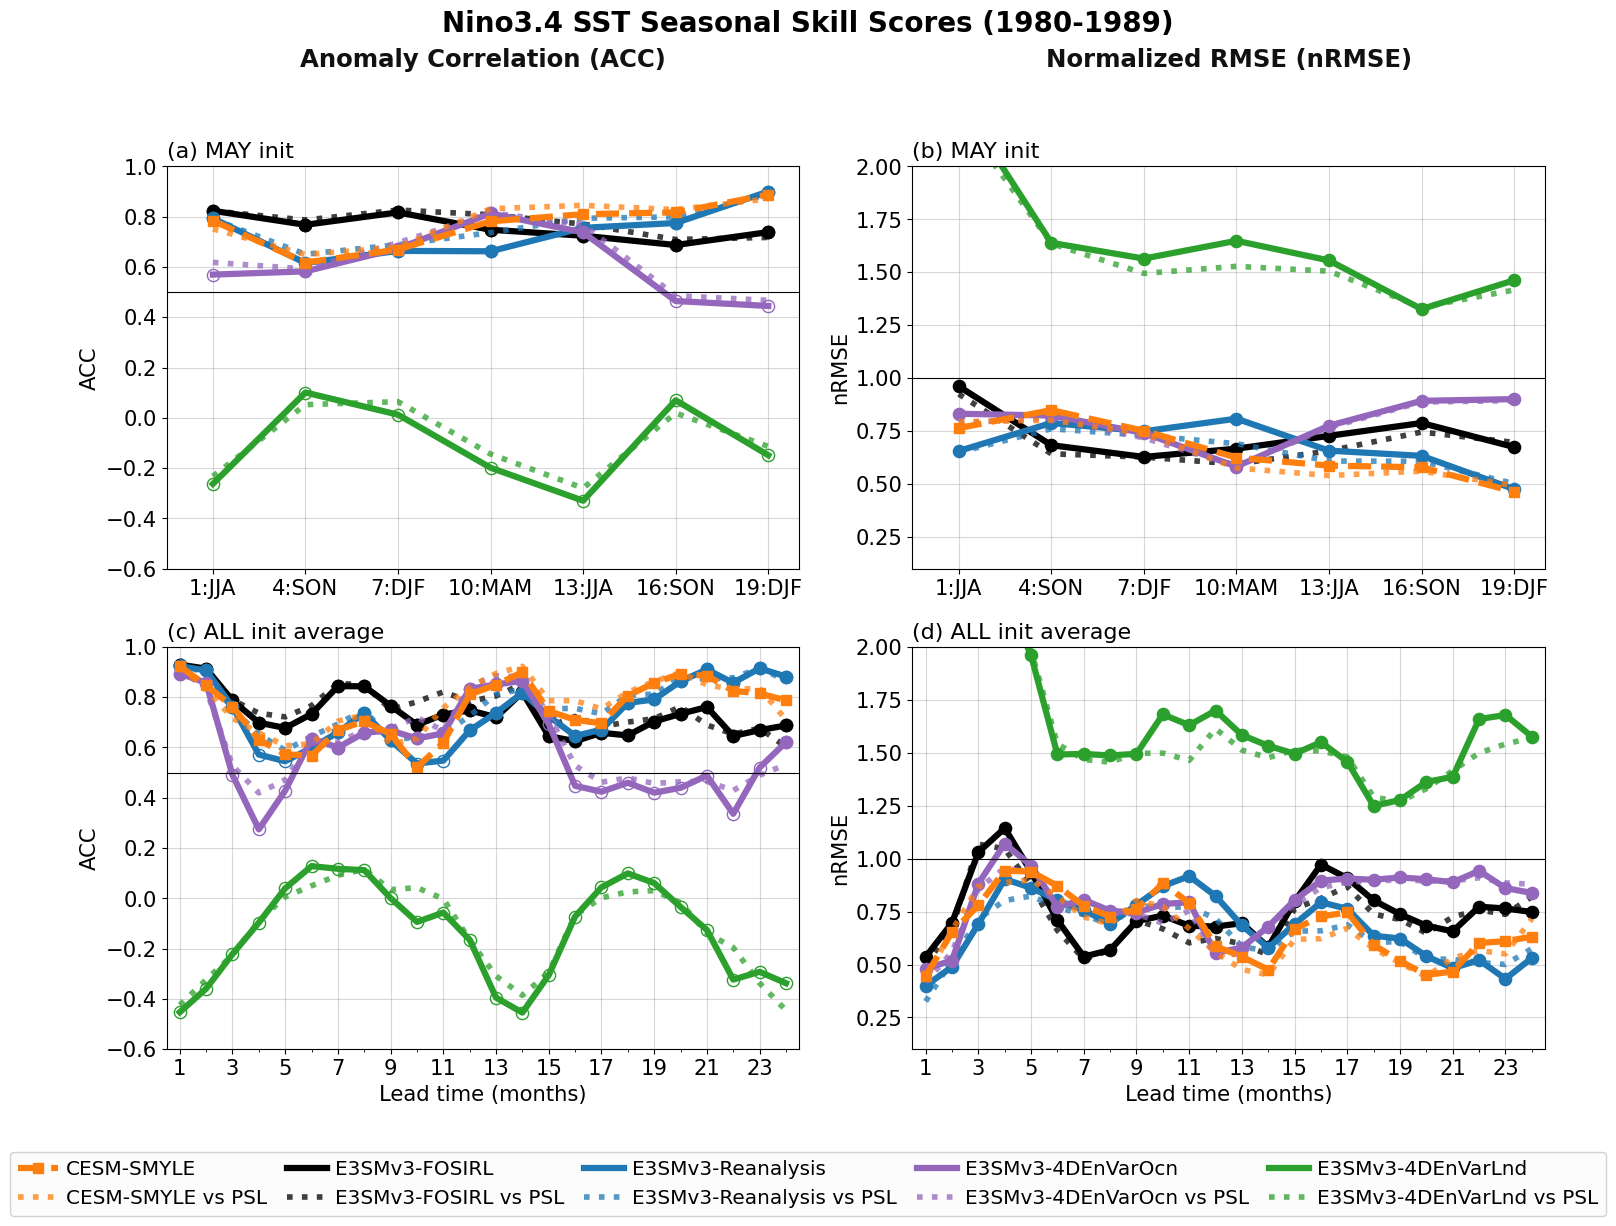

In [15]:
# -----------------------------
# Plot skill scores
# -----------------------------
# =============================================================================
# Setup Parameters
# =============================================================================
skill_plot_cfg = WORKFLOW_SETTINGS["skill_plot"]
field = cfg.region_name
figfmt = skill_plot_cfg["figfmt"]
period = f"{skill_year0}-{skill_year1}"
figname = figure_filename("sst_index", field, "acc_skill", ext=figfmt)
dpi = skill_plot_cfg.get("dpi", 300)
save_bbox = skill_plot_cfg.get("save_bbox", "tight")

# Layout & geometry
ncol = skill_plot_cfg.get("ncol", 2)
startmonths_requested = (
    cfg.init_months
    if skill_plot_cfg.get("startmonths", "cfg") == "cfg"
    else list(skill_plot_cfg["startmonths"])
)
startmonths = [
    m for m in startmonths_requested
    if any(m in skill.startmonth.values for skill in e3smle_seas_skill_by_case.values())
]
nrow = len(startmonths) + 1

fig_width = skill_plot_cfg.get("fig_width", 14.0)
fig_height = skill_plot_cfg.get("fig_height", 12.5)
fig_size = (fig_width, fig_height)

# Typography & scaling factors
fontz = skill_plot_cfg.get("fontz", 14)
scale_header = 1.1
scale_title = 1.0
scale_label = 0.95
scale_tick = 0.95
scale_legend = 0.90

header_fontz = fontz * scale_header
title_fontz = fontz * scale_title
label_fontz = fontz * scale_label
tick_fontz = fontz * scale_tick
legend_fontz = fontz * scale_legend

# Margins & legend placement
tight_layout_rect = [0.03, 0.09, 0.98, 0.94]
xlabel_text = "Lead time (months)"

# Styling
line_width = skill_plot_cfg.get("line_width", 1.8)
marker_size = fontz * 0.55
e3sm_marker_size = marker_size
smyle_marker_size = marker_size * 0.75
nmme_marker_size = marker_size * 0.75

smyle_label = skill_plot_cfg.get("smyle_label", "CESM-SMYLE")
smyle_color = skill_plot_cfg.get("smyle_color", "tab:orange")
smyle_linestyle = skill_plot_cfg.get("smyle_linestyle", "--")
nmme_color = skill_plot_cfg.get("nmme_color", "tab:red")
nmme_linestyle = skill_plot_cfg.get("nmme_linestyle", "-.")
nmme_label = skill_plot_cfg.get("nmme_label", "NMME")
nmme_marker = skill_plot_cfg.get("nmme_marker", "^")
nmme_spread_alpha = skill_plot_cfg.get("nmme_spread_alpha", 0.16)
psl_linestyle = skill_plot_cfg.get("psl_linestyle", ":")
psl_alpha = skill_plot_cfg.get("psl_alpha", 0.75)
psl_line_width = line_width * 0.9
e3sm_marker = skill_plot_cfg.get("e3sm_marker", "o")
smyle_marker = skill_plot_cfg.get("smyle_marker", "s")
significance_pval = skill_plot_cfg.get("significance_pval", 0.05)
open_marker_fillstyle = skill_plot_cfg.get("open_marker_fillstyle", "none")
marker_only_linestyle = skill_plot_cfg.get("marker_only_linestyle", "none")

hindcast_label = {2: "FEB init", 5: "MAY init", 8: "AUG init", 11: "NOV init"}
all_init_label = "ALL init average"

season_labels_by_month = {
    2:  ["MAM", "JJA", "SON", "DJF", "MAM", "JJA", "SON", "DJF", "MAM", "JJA", "SON", "DJF"],
    5:  ["JJA", "SON", "DJF", "MAM", "JJA", "SON", "DJF", "MAM", "JJA", "SON", "DJF", "MAM"],
    8:  ["SON", "DJF", "MAM", "JJA", "SON", "DJF", "MAM", "JJA", "SON", "DJF", "MAM", "JJA"],
    11: ["DJF", "MAM", "JJA", "SON", "DJF", "MAM", "JJA", "SON", "DJF", "MAM", "JJA", "SON"],
}

acc_ylim = plot_settings["acc_lim"]
seasonal_rmse_ylim = plot_settings["rmse_lim"]
monthly_rmse_ylim = plot_settings["rmse_lim"]
acc_hline = skill_plot_cfg.get("acc_hline", 0.5)
rmse_hline = skill_plot_cfg.get("rmse_hline", 1.0)
hline_color = skill_plot_cfg.get("hline_color", "gray")
show_grid = skill_plot_cfg.get("show_grid", True)
monthly_xticks = np.arange(12) * 2 + 1
monthly_xticks_minor = np.arange(2, 25, 2)

_seasonal_core = e3smle_seas_skill[["corr", "rmse"]].to_array()
_seasonal_reduce_dims = [dim for dim in _seasonal_core.dims if dim != "L"]
_seasonal_lead_available = _seasonal_core.notnull().any(_seasonal_reduce_dims)
seasonal_lead_offset = 2
leadsea = (
    e3smle_seas_skill.L.where(_seasonal_lead_available, drop=True)
    - seasonal_lead_offset
)
_nlead_seas = leadsea.sizes["L"]
seasonal_xlim = [-0.5, float(leadsea.max()) + 1.0]
monthly_xlim = [0.5, 24.5]

xsea = {
    month: labels[:_nlead_seas]
    for month, labels in season_labels_by_month.items()
}
figlabs = [f"({chr(97 + i)})" for i in range(nrow * ncol)]

# =============================================================================
# Plotting
# =============================================================================
plt.rcParams.update({
    "font.size": fontz,
    "axes.titlesize": title_fontz,
    "xtick.labelsize": tick_fontz,
    "ytick.labelsize": tick_fontz,
    "legend.fontsize": legend_fontz,
})

fig = plt.figure(figsize=fig_size)
top_axes = []

# -----------------------------
# 1. Seasonal initialization panels
# -----------------------------
for ind, sm in enumerate(startmonths):
    ax = fig.add_subplot(nrow, ncol, ind * 2 + 1)
    ax2 = fig.add_subplot(nrow, ncol, ind * 2 + 2)
    if ind == 0:
        top_axes = [ax, ax2]

    sm_int = int(sm)
    label = hindcast_label.get(sm_int, f"{sm_int:02d} init")

    ax.set_title(
        f"{figlabs[ind * 2]} {label}",
        loc="left",
        fontsize=title_fontz,
        fontweight="medium",
    )
    ax2.set_title(
        f"{figlabs[ind * 2 + 1]} {label}",
        loc="left",
        fontsize=title_fontz,
        fontweight="medium",
    )

    ax.set_ylabel("ACC", fontsize=label_fontz)
    ax2.set_ylabel("nRMSE", fontsize=label_fontz)

    for case_key, case_info in E3SM_ACTIVE_CASES.items():
        if case_key not in e3smle_seas_skill_by_case or sm not in e3smle_seas_skill_by_case[case_key].startmonth.values:
            continue
        case_color = case_info["color"]
        case_label = case_info["display_name"]
        case_ls = case_info.get("linestyle", "-")
        tmp = e3smle_seas_skill_by_case[case_key].sel(startmonth=sm)

        plot_lead = tmp.L - seasonal_lead_offset
        ax.plot(plot_lead, tmp.corr, color=case_color, linewidth=line_width, linestyle=case_ls, label=case_label)
        ax.plot(plot_lead, tmp.corr, color=case_color, marker=e3sm_marker, markersize=e3sm_marker_size, fillstyle=open_marker_fillstyle, linestyle=marker_only_linestyle)
        ax.plot(plot_lead, tmp.corr.where(tmp.pval < significance_pval), color=case_color, marker=e3sm_marker, markersize=e3sm_marker_size, linestyle=marker_only_linestyle)

        ax2.plot(plot_lead, tmp.rmse, color=case_color, linewidth=line_width, linestyle=case_ls, marker=e3sm_marker, markersize=e3sm_marker_size, label=case_label)

        if (
            case_key in e3smle_seas_skill_ref_by_case
            and sm in e3smle_seas_skill_ref_by_case[case_key].startmonth.values
            and "reference" in e3smle_seas_skill_ref_by_case[case_key].coords
            and "PSL" in e3smle_seas_skill_ref_by_case[case_key].reference.values
        ):
            tmp_psl = e3smle_seas_skill_ref_by_case[case_key].sel(startmonth=sm, reference="PSL")
            plot_lead_psl = tmp_psl.L - seasonal_lead_offset
            ax.plot(plot_lead_psl, tmp_psl.corr, color=case_color, linewidth=psl_line_width, linestyle=psl_linestyle, alpha=psl_alpha, label=f"{case_label} vs PSL")
            ax2.plot(plot_lead_psl, tmp_psl.rmse, color=case_color, linewidth=psl_line_width, linestyle=psl_linestyle, alpha=psl_alpha, label=f"{case_label} vs PSL")

    if (
        "smyle_seas_skill_plot" in globals()
        and sm in smyle_seas_skill_plot.startmonth.values
    ):
        tmp_smyle = smyle_seas_skill_plot.sel(startmonth=sm)
        plot_lead_smyle = tmp_smyle.L - seasonal_lead_offset
        ax.plot(plot_lead_smyle, tmp_smyle.corr, color=smyle_color, linewidth=line_width, linestyle=smyle_linestyle, marker=smyle_marker, markersize=smyle_marker_size, label=smyle_label)
        ax2.plot(plot_lead_smyle, tmp_smyle.rmse, color=smyle_color, linewidth=line_width, linestyle=smyle_linestyle, marker=smyle_marker, markersize=smyle_marker_size, label=smyle_label)

    if (
        "smyle_seas_skill_ref" in globals()
        and sm in smyle_seas_skill_ref.startmonth.values
        and "reference" in smyle_seas_skill_ref.coords
        and "PSL" in smyle_seas_skill_ref.reference.values
    ):
        tmp_smyle_psl = smyle_seas_skill_ref.sel(startmonth=sm, reference="PSL")
        plot_lead_smyle_psl = tmp_smyle_psl.L - seasonal_lead_offset
        ax.plot(plot_lead_smyle_psl, tmp_smyle_psl.corr, color=smyle_color, linewidth=psl_line_width, linestyle=psl_linestyle, alpha=psl_alpha, label=f"{smyle_label} vs PSL")
        ax2.plot(plot_lead_smyle_psl, tmp_smyle_psl.rmse, color=smyle_color, linewidth=psl_line_width, linestyle=psl_linestyle, alpha=psl_alpha, label=f"{smyle_label} vs PSL")

    if (
        "nmme_seas_skill_plot" in globals()
        and sm in nmme_seas_skill_plot.startmonth.values
    ):
        tmp_nmme = nmme_seas_skill_plot.sel(startmonth=sm)
        plot_lead_nmme = tmp_nmme.L - seasonal_lead_offset
        ax.plot(plot_lead_nmme, tmp_nmme.corr, color=nmme_color, linewidth=line_width, linestyle=nmme_linestyle, marker=nmme_marker, markersize=nmme_marker_size, label=nmme_label)
        ax.plot(plot_lead_nmme, tmp_nmme.corr.where(tmp_nmme.pval < significance_pval), color=nmme_color, marker=nmme_marker, markersize=nmme_marker_size, linestyle=marker_only_linestyle)
        ax2.plot(plot_lead_nmme, tmp_nmme.rmse, color=nmme_color, linewidth=line_width, linestyle=nmme_linestyle, marker=nmme_marker, markersize=nmme_marker_size, label=nmme_label)

        if "nmme_seas_skill_spread" in globals() and sm in nmme_seas_skill_spread.startmonth.values:
            tmp_nmme_spread = nmme_seas_skill_spread.sel(startmonth=sm)
            nmme_spread_dim = "model" if "model" in tmp_nmme_spread.dims else None
            if nmme_spread_dim:
                plot_lead_nmme_spread = tmp_nmme_spread.L.data - seasonal_lead_offset
                ax.fill_between(plot_lead_nmme_spread, tmp_nmme_spread.corr.min(nmme_spread_dim, skipna=True), tmp_nmme_spread.corr.max(nmme_spread_dim, skipna=True), fc=nmme_color, alpha=nmme_spread_alpha, linewidth=0)
                ax2.fill_between(plot_lead_nmme_spread, tmp_nmme_spread.rmse.min(nmme_spread_dim, skipna=True), tmp_nmme_spread.rmse.max(nmme_spread_dim, skipna=True), fc=nmme_color, alpha=nmme_spread_alpha, linewidth=0)

    _nlead_seas = min(len(leadsea), len(xsea.get(sm_int, [])))
    xticklabs = [f"{int(leadsea[i].data)}:{xsea[sm_int][i]}" for i in range(_nlead_seas)]
    ax.set_xticks(leadsea)
    ax.set_xticklabels(xticklabs, fontsize=tick_fontz)
    ax.set_xlim(seasonal_xlim)
    ax.set_ylim(acc_ylim)
    ax.tick_params(axis="both", labelsize=tick_fontz)
    ax.grid(show_grid, alpha=0.5)
    ax.axhline(y=acc_hline, color=hline_color, linewidth=0.8)

    ax2.set_xticks(leadsea)
    ax2.set_xticklabels(xticklabs, fontsize=tick_fontz)
    ax2.set_xlim(seasonal_xlim)
    ax2.set_ylim(seasonal_rmse_ylim)
    ax2.tick_params(axis="both", labelsize=tick_fontz)
    ax2.grid(show_grid, alpha=0.5)
    ax2.axhline(y=rmse_hline, color=hline_color, linewidth=0.8)

# -----------------------------
# 2. Monthly ALL-init average panels
# -----------------------------
bottom_row = len(startmonths)
ax = fig.add_subplot(nrow, ncol, bottom_row * 2 + 1)
ax2 = fig.add_subplot(nrow, ncol, bottom_row * 2 + 2)

ax.set_title(f"{figlabs[bottom_row * 2]} {all_init_label}", loc="left", fontsize=title_fontz, fontweight="medium")
ax2.set_title(f"{figlabs[bottom_row * 2 + 1]} {all_init_label}", loc="left", fontsize=title_fontz, fontweight="medium")

ax.set_ylabel("ACC", fontsize=label_fontz)
ax2.set_ylabel("nRMSE", fontsize=label_fontz)

# Cases covering only some months are averaged over the months they have.
partial_month_notes = [
    f"{case_info['display_name']}: "
    + "/".join(hindcast_label.get(m, f"{m:02d}").split()[0] for m in case_info["init_years"])
    for case_info in E3SM_ACTIVE_CASES.values()
    if list(case_info["init_years"]) != list(cfg.init_months)
]
if partial_month_notes:
    ax.text(0.02, 0.03, "Averaged over\n" + "\n".join(partial_month_notes),
            transform=ax.transAxes, fontsize=label_fontz * 0.6, va="bottom")

for case_key, case_info in E3SM_ACTIVE_CASES.items():
    if case_key not in e3smle_skill_by_case:
        continue
    case_color = case_info["color"]
    case_label = case_info["display_name"]
    case_ls    = case_info.get("linestyle", "-")
    tmp = e3smle_skill_by_case[case_key].mean("startmonth")

    ax.plot(tmp.L, tmp.corr, color=case_color, linewidth=line_width, linestyle=case_ls, label=case_label)
    ax.plot(tmp.L, tmp.corr, color=case_color, marker=e3sm_marker, markersize=e3sm_marker_size, fillstyle=open_marker_fillstyle, linestyle=marker_only_linestyle)
    ax.plot(tmp.L, tmp.corr.where(tmp.pval < significance_pval), color=case_color, marker=e3sm_marker, markersize=e3sm_marker_size, linestyle=marker_only_linestyle)

    ax2.plot(tmp.L, tmp.rmse, color=case_color, linewidth=line_width, linestyle=case_ls, marker=e3sm_marker, markersize=e3sm_marker_size, label=case_label)

    if (
        case_key in e3smle_skill_ref_by_case
        and "reference" in e3smle_skill_ref_by_case[case_key].coords
        and "PSL" in e3smle_skill_ref_by_case[case_key].reference.values
    ):
        tmp_psl = e3smle_skill_ref_by_case[case_key].sel(reference="PSL").mean("startmonth")
        ax.plot(tmp_psl.L, tmp_psl.corr, color=case_color, linewidth=psl_line_width, linestyle=psl_linestyle, alpha=psl_alpha, label=f"{case_label} vs PSL")
        ax2.plot(tmp_psl.L, tmp_psl.rmse, color=case_color, linewidth=psl_line_width, linestyle=psl_linestyle, alpha=psl_alpha, label=f"{case_label} vs PSL")

if "smyle_skill_plot" in globals():
    tmp_smyle = smyle_skill_plot.mean("startmonth")
    ax.plot(tmp_smyle.L, tmp_smyle.corr, color=smyle_color, linewidth=line_width, linestyle=smyle_linestyle, marker=smyle_marker, markersize=smyle_marker_size, label=smyle_label)
    ax2.plot(tmp_smyle.L, tmp_smyle.rmse, color=smyle_color, linewidth=line_width, linestyle=smyle_linestyle, marker=smyle_marker, markersize=smyle_marker_size, label=smyle_label)

if (
    "smyle_skill_ref" in globals()
    and "reference" in smyle_skill_ref.coords
    and "PSL" in smyle_skill_ref.reference.values
):
    tmp_smyle_psl = smyle_skill_ref.sel(reference="PSL").mean("startmonth")
    ax.plot(tmp_smyle_psl.L, tmp_smyle_psl.corr, color=smyle_color, linewidth=psl_line_width, linestyle=psl_linestyle, alpha=psl_alpha, label=f"{smyle_label} vs PSL")
    ax2.plot(tmp_smyle_psl.L, tmp_smyle_psl.rmse, color=smyle_color, linewidth=psl_line_width, linestyle=psl_linestyle, alpha=psl_alpha, label=f"{smyle_label} vs PSL")

if "nmme_skill_plot" in globals():
    tmp_nmme = nmme_skill_plot.mean("startmonth")
    ax.plot(tmp_nmme.L, tmp_nmme.corr, color=nmme_color, linewidth=line_width, linestyle=nmme_linestyle, marker=nmme_marker, markersize=nmme_marker_size, label=nmme_label)
    ax.plot(tmp_nmme.L, tmp_nmme.corr.where(tmp_nmme.pval < significance_pval), color=nmme_color, marker=nmme_marker, markersize=nmme_marker_size, linestyle=marker_only_linestyle)
    ax2.plot(tmp_nmme.L, tmp_nmme.rmse, color=nmme_color, linewidth=line_width, linestyle=nmme_linestyle, marker=nmme_marker, markersize=nmme_marker_size, label=nmme_label)

    if "nmme_skill_spread" in globals():
        tmp_nmme_spread = nmme_skill_spread
        nmme_spread_dims = [dim for dim in ("startmonth", "model") if dim in tmp_nmme_spread.dims]
        ax.fill_between(tmp_nmme_spread.L.data, tmp_nmme_spread.corr.min(nmme_spread_dims, skipna=True), tmp_nmme_spread.corr.max(nmme_spread_dims, skipna=True), fc=nmme_color, alpha=nmme_spread_alpha, linewidth=0)
        ax2.fill_between(tmp_nmme_spread.L.data, tmp_nmme_spread.rmse.min(nmme_spread_dims, skipna=True), tmp_nmme_spread.rmse.max(nmme_spread_dims, skipna=True), fc=nmme_color, alpha=nmme_spread_alpha, linewidth=0)

for a, yl, hl in [(ax, acc_ylim, acc_hline), (ax2, monthly_rmse_ylim, rmse_hline)]:
    a.set_xticks(monthly_xticks)
    a.set_xticks(monthly_xticks_minor, minor=True)
    a.tick_params(axis="both", labelsize=tick_fontz)
    a.set_xlim(monthly_xlim)
    a.set_ylim(yl)
    a.grid(show_grid, alpha=0.5)
    a.axhline(y=hl, color=hline_color, linewidth=0.8)
    a.set_xlabel(xlabel_text, fontsize=label_fontz)

# -----------------------------
# 3. Legend and layout
# -----------------------------
handles, labels = ax.get_legend_handles_labels()
legend_items = {l: h for h, l in zip(handles, labels) if l}

models_in_order = [nmme_label, smyle_label] + [case_info["display_name"] for case_info in E3SM_ACTIVE_CASES.values()]
row0_labels = []
row1_labels = []

for m in models_in_order:
    if m in legend_items:
        row0_labels.append(m)
        if m == nmme_label and "nmme_skill_spread" in globals():
            legend_items["NMME range"] = mpatches.Patch(facecolor=nmme_color, alpha=nmme_spread_alpha, linewidth=0)
            row1_labels.append("NMME range")
        else:
            psl_l = f"{m} vs PSL"
            if psl_l in legend_items:
                row1_labels.append(psl_l)
            else:
                row1_labels.append(None)

col_major_handles = []
col_major_labels = []
for r0, r1 in zip(row0_labels, row1_labels):
    col_major_handles.append(legend_items[r0])
    col_major_labels.append(r0)
    if r1 is not None and r1 in legend_items:
        col_major_handles.append(legend_items[r1])
        col_major_labels.append(r1)
    else:
        col_major_handles.append(mpatches.Patch(color="none", alpha=0))
        col_major_labels.append("")

fig.legend(
    col_major_handles, col_major_labels,
    loc="lower center",
    ncol=len(row0_labels),
    bbox_to_anchor=(0.5, 0.012),
    frameon=True,
    facecolor="#fcfcfc",
    edgecolor="#d0d0d0",
    framealpha=0.95,
    fontsize=legend_fontz,
    columnspacing=1.0,
    handletextpad=0.4,
)

fig.suptitle(f"{cfg.region_name} SST Seasonal Skill Scores ({period})", fontsize=fontz * 1.25, fontweight="bold", y=0.985)
fig.tight_layout(rect=tight_layout_rect)

pos0 = top_axes[0].get_position()
pos1 = top_axes[1].get_position()
fig.text(pos0.x0 + pos0.width * 0.5, 0.945, "Anomaly Correlation (ACC)", ha="center", va="center",
         fontsize=header_fontz, fontweight="bold", color="#111111")
fig.text(pos1.x0 + pos1.width * 0.5, 0.945, "Normalized RMSE (nRMSE)", ha="center", va="center",
         fontsize=header_fontz, fontweight="bold", color="#111111")

figpath = FIGURE_OUTDIR / figname
mov.save_figure(
    fig, figpath,
    mode="",
    metric=f"{cfg.region_name.lower()}_sst_skill",
    title=f"{cfg.region_name} SST Skill",
    caption=f"Common initialization-year verification cohort: {period}",
    dpi=dpi,
)
print("Saved figure:", figpath)
plt.show()


In [16]:
# -----------------------------
# DJF observed anomaly series
# -----------------------------
print(obs_seas.time)

jan = obs_seas.time.dt.month == 1
obs_djf = obs_seas.where(jan).dropna("time")
obs_djf = obs_djf - obs_djf.sel(time=slice(str(climy0), str(climy1))).mean("time")

if psl_sst_index_reference_available:
    psl_djf = psl_seas.where(psl_seas.time.dt.month == 1).dropna("time")
    # Realign PSL anomaly to the exact same climatology baseline period (climy0, climy1)
    psl_djf = psl_djf - psl_djf.sel(time=slice(str(climy0), str(climy1))).mean("time")
elif "psl_djf" in globals():
    del psl_djf


<xarray.DataArray 'time' (time: 1846)> Size: 15kB
array([cftime.DatetimeNoLeap(1869, 2, 15, 0, 0, 0, 0, has_year_zero=True),
       cftime.DatetimeNoLeap(1869, 3, 15, 0, 0, 0, 0, has_year_zero=True),
       cftime.DatetimeNoLeap(1869, 4, 15, 0, 0, 0, 0, has_year_zero=True), ...,
       cftime.DatetimeNoLeap(2022, 9, 15, 0, 0, 0, 0, has_year_zero=True),
       cftime.DatetimeNoLeap(2022, 10, 15, 0, 0, 0, 0, has_year_zero=True),
       cftime.DatetimeNoLeap(2022, 11, 15, 0, 0, 0, 0, has_year_zero=True)],
      shape=(1846,), dtype=object)
Coordinates:
  * time     (time) object 15kB 1869-02-15 00:00:00 ... 2022-11-15 00:00:00


In [17]:
# -----------------------------
# Combine seasonal drift-corrected series (all cases)
# (order follows cfg.init_months)
# -----------------------------
startmonth = xr.DataArray(cfg.init_months, name="startmonth", dims="startmonth")

e3smle_seas_by_case      = {}
e3smle_seas_time_by_case = {}
e3smle_seas_skill_plot_by_case     = {}
e3smle_seas_skill_ref_plot_by_case = {}

for case_key in E3SM_ACTIVE_CASES:
    case_results    = results_by_case[case_key]
    case_results_dd = results_dd_by_case[case_key]
    case_skill      = results_skill_by_case[case_key]
    case_months     = [m for m in cfg.init_months if m in case_skill]
    startmonth      = xr.DataArray(case_months, name="startmonth", dims="startmonth")

    e3smle_seas_by_case[case_key] = xr.concat(
        [case_results_dd[m]["seas_dd"] for m in case_months], dim=startmonth, join="outer"
    )
    e3smle_seas_time_by_case[case_key] = xr.concat(
        [case_results[m]["time_seas"] for m in case_months], dim=startmonth, join="outer"
    )
    e3smle_seas_skill_plot_by_case[case_key] = xr.concat(
        [case_skill[m]["skill_seas"] for m in case_months], dim=startmonth, join="outer"
    )
    e3smle_seas_skill_ref_plot_by_case[case_key] = xr.concat(
        [case_skill[m]["skill_ref_seas"] for m in case_months], dim=startmonth, join="outer"
    )

# Backward-compatible reference-case aliases
e3smle_seas           = e3smle_seas_by_case[E3SM_REFERENCE_CASE]
e3smle_seas_time      = e3smle_seas_time_by_case[E3SM_REFERENCE_CASE]
e3smle_seas_skill_plot     = e3smle_seas_skill_plot_by_case[E3SM_REFERENCE_CASE]
e3smle_seas_skill_ref_plot = e3smle_seas_skill_ref_plot_by_case[E3SM_REFERENCE_CASE]

print("Seasonal drift-corrected E3SM series by case:")
for case_key, seas_da in e3smle_seas_by_case.items():
    print(f"  {case_key}: series sizes={dict(seas_da.sizes)}")
print(f"Reference case time sizes={dict(e3smle_seas_time.sizes)}")
print(f"Reference case skill sizes={dict(e3smle_seas_skill_plot.sizes)}")


Seasonal drift-corrected E3SM series by case:
  E3SM-FOSIRL: series sizes={'startmonth': 1, 'Y': 16, 'L': 7, 'M': 10}
  E3SM-Reanalysis: series sizes={'startmonth': 1, 'Y': 16, 'L': 7, 'M': 10}
  E3SM-4DEnVarOcn: series sizes={'startmonth': 1, 'Y': 16, 'L': 7, 'M': 10}
  E3SM-4DEnVarLnd: series sizes={'startmonth': 1, 'Y': 10, 'L': 7, 'M': 10}
Reference case time sizes={'startmonth': 1, 'Y': 16, 'L': 7}
Reference case skill sizes={'startmonth': 1, 'L': 7}


Saved figure: /global/cfs/cdirs/e3sm/www/zhan391/e3sm-s2d_test/sample_figures/fig_sst_index_nino3_4_time_series.png


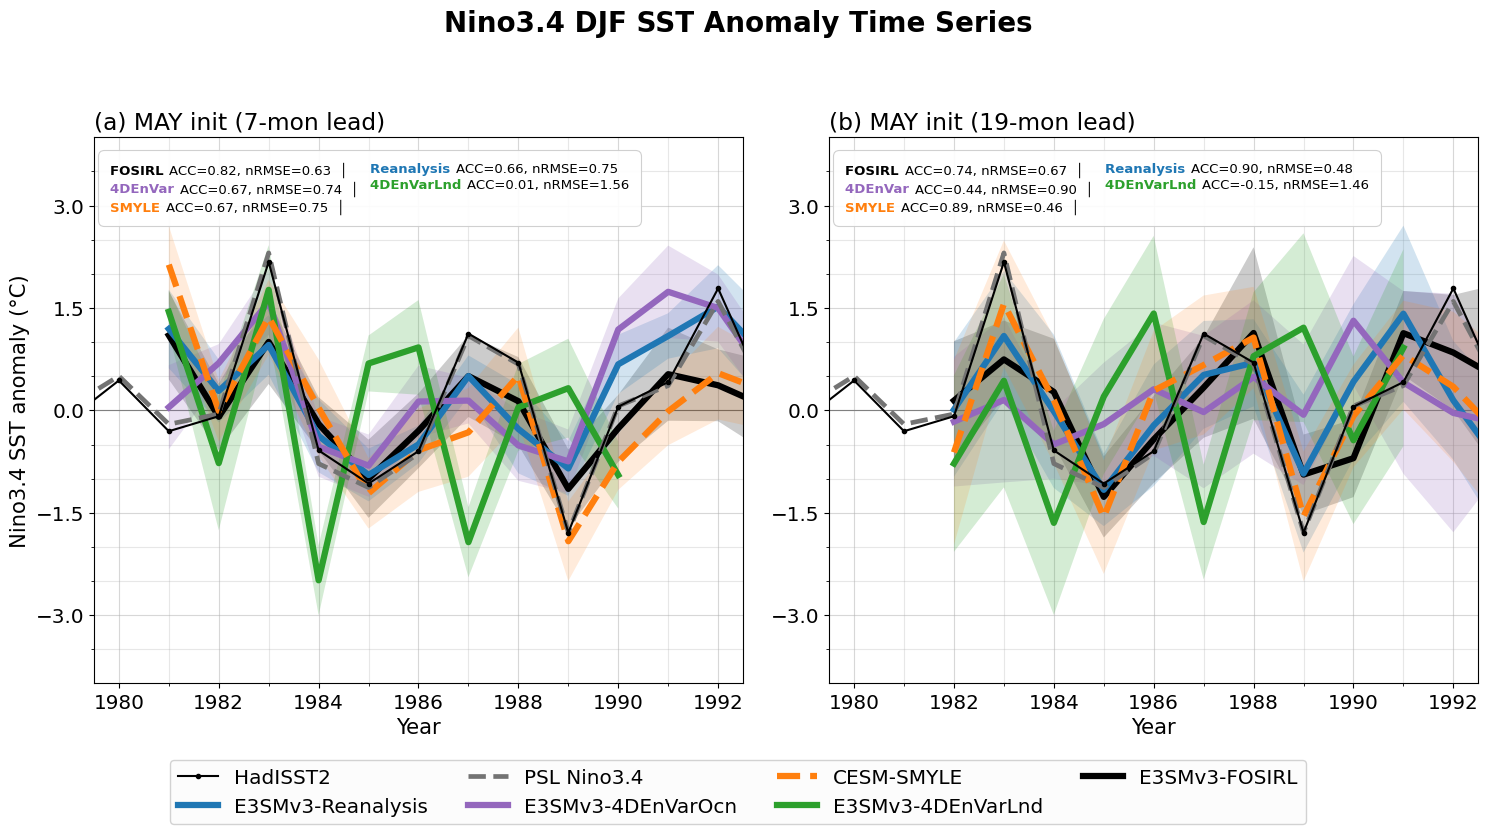

In [18]:
# -----------------------------
# Plot DJF SST-index time series
# -----------------------------
# =============================================================================
# Setup Parameters
# =============================================================================
import pandas as pd
from matplotlib.offsetbox import AnchoredOffsetbox, HPacker, VPacker, TextArea

ts_plot_cfg = WORKFLOW_SETTINGS["timeseries_plot"]
field = cfg.region_name
figfmt = ts_plot_cfg.get("figfmt", "png")
period = f"{years}-{yeare}"
figname = figure_filename("sst_index", field, "time_series", ext=figfmt)
dpi = ts_plot_cfg.get("dpi", 300)

# Layout & geometry
startmonths_requested = list(ts_plot_cfg.get("startmonths", [11, 5]))
djf_leads = dict(ts_plot_cfg.get("djf_leads", {11: [3, 15], 5: [9, 21]}))
startmonths_plot = [
    m for m in startmonths_requested
    if any(m in seas.startmonth.values for seas in e3smle_seas_by_case.values())
]
nrow = len(startmonths_plot)
ncol = ts_plot_cfg.get("ncol", 2)

# Figure geometry
fig_width = ts_plot_cfg.get("fig_width", 14.0)
fig_height = ts_plot_cfg.get("fig_height", 8.5)
fig_size = (fig_width, fig_height)

# Typography & scaling factors
fontz = ts_plot_cfg.get("fontz", 13)
scale_title = 1.05
scale_label = 0.95
scale_tick = 0.90
scale_legend = 0.90
scale_annot = 0.80

title_fontz = fontz * scale_title
label_fontz = fontz * scale_label
tick_fontz = fontz * scale_tick
legend_fontz = fontz * scale_legend
annot_fontz = min(fontz * scale_annot, 9.5)

# Margins & legend placement
tight_layout_rect = [0.03, 0.10, 0.98, 0.955]
legend_bbox = (0.5, 0.015)
legend_ncol = 4

# Styling
line_width = ts_plot_cfg.get("line_width", 2.0)
obs_marker_size = ts_plot_cfg.get("obs_marker_size", 5.0)
e3sm_spread_alpha = ts_plot_cfg.get("e3sm_spread_alpha", 0.18)
smyle_spread_alpha = ts_plot_cfg.get("smyle_spread_alpha", 0.18)
smyle_color = ts_plot_cfg.get("smyle_color", "tab:orange")
nmme_color = ts_plot_cfg.get("nmme_color", "tab:red")
nmme_linestyle = ts_plot_cfg.get("nmme_linestyle", "-.")
nmme_spread_alpha = ts_plot_cfg.get("nmme_spread_alpha", 0.15)
obs_color = ts_plot_cfg.get("obs_color", "k")
psl_obs_color = ts_plot_cfg.get("psl_obs_color", "0.45")
psl_obs_linestyle = ts_plot_cfg.get("psl_obs_linestyle", "--")
grid_minor_alpha = ts_plot_cfg.get("grid_minor_alpha", 0.25)

# Axes limits and ticks
plot_ylim = list(plot_settings["ts_lim"])
major_yticks = plot_settings["ts_yticks"]
minor_yticks = np.arange(plot_ylim[0] + 0.5, plot_ylim[1], 0.5)
plot_xmin = ts_plot_cfg.get("plot_xmin", 1979.5)
plot_xmax = ts_plot_cfg.get("plot_xmax", 2020.5)
major_years = ts_plot_cfg.get("major_years", [1980, 1990, 2000, 2010, 2020])
minor_years = ts_plot_cfg.get("minor_years", np.arange(1980, 2021, 2))

hindcast_label = {11: "NOV", 5: "MAY"}
figlabs = [["(a)", "(c)"], ["(b)", "(d)"]]
psl_obs_label = "PSL DMI" if cfg.region_name == "IOD" else f"PSL {cfg.region_name}"

def _year_values(time_da):
    values = np.asarray(time_da.values).ravel()
    out = []
    for t in values:
        val = np.nan
        if t is not None:
            if hasattr(t, "year"):
                val = t.year
            else:
                ts = pd.Timestamp(t)
                if not pd.isna(ts):
                    val = ts.year
        out.append(val)
    return np.asarray(out, dtype=float)

# =============================================================================
# Plotting
# =============================================================================
plt.rcParams.update({
    "font.size": fontz,
    "axes.titlesize": title_fontz,
    "xtick.labelsize": tick_fontz,
    "ytick.labelsize": tick_fontz,
    "legend.fontsize": legend_fontz,
})

fig = plt.figure(figsize=(fig_width, fig_height))

for i, sm in enumerate(startmonths_plot):
    ax = fig.add_subplot(nrow, ncol, i * 2 + 1)
    ax2 = fig.add_subplot(nrow, ncol, i * 2 + 2)

    for a in [ax, ax2]:
        a.set_ylim(plot_ylim)
        a.set_yticks(major_yticks)
        a.set_yticks(minor_yticks, minor=True)
        a.set_xlim([plot_xmin, plot_xmax])
        a.set_xticks(major_years)
        a.set_xticks(minor_years, minor=True)
        a.tick_params(axis="both", labelsize=tick_fontz)

        if "obs_djf" in globals():
            a.plot(obs_djf.time.dt.year, obs_djf, color="k", marker=".", markersize=obs_marker_size, label="HadISST2", zorder=6)
        if "psl_djf" in globals():
            a.plot(psl_djf.time.dt.year, psl_djf, color="0.45", linestyle="--", linewidth=line_width * 0.75, label=psl_obs_label, zorder=5)

        a.grid(True, which="major", alpha=0.5)
        a.grid(True, which="minor", alpha=grid_minor_alpha)
        a.axhline(0, color="gray", linestyle="-", linewidth=0.8)

    for col_idx, (ax_panel, target_L) in enumerate(zip([ax, ax2], djf_leads[sm])):
        lead = int(target_L) - 2
        titl = f"{hindcast_label.get(sm, f'Init {sm}')} init ({lead}-mon lead)"
        figlabel = figlabs[col_idx][i] if (col_idx < len(figlabs) and i < len(figlabs[col_idx])) else f"({panel_idx})"
        ax_panel.set_title(f"{figlabel} {titl}", loc="left", fontsize=title_fontz, fontweight="medium")

        if i == nrow - 1:
            ax_panel.set_xlabel("Year", fontsize=label_fontz)
        if col_idx == 0:
            ax_panel.set_ylabel(f"{cfg.region_name} SST anomaly (°C)", fontsize=label_fontz)

        metrics = []

        # E3SM Hindcasts
        for case_key, case_info in E3SM_ACTIVE_CASES.items():
            if (case_key not in e3smle_seas_by_case or case_key not in e3smle_seas_time_by_case or case_key not in e3smle_seas_skill_plot_by_case or sm not in e3smle_seas_by_case[case_key].startmonth.values or target_L not in e3smle_seas_by_case[case_key].sel(startmonth=sm).L.values):
                continue
            case_color = case_info["color"]
            case_label = case_info["display_name"]
            case_ls    = case_info.get("linestyle", "-")

            case_data       = e3smle_seas_by_case[case_key].sel(startmonth=sm, L=target_L)
            case_tmp_time   = e3smle_seas_time_by_case[case_key].sel(startmonth=sm, L=target_L)
            case_skill_row  = e3smle_seas_skill_plot_by_case[case_key].sel(startmonth=sm, L=target_L)

            case_acc   = float(case_skill_row.corr.values)
            case_nrmse = float(case_skill_row.rmse.values)

            case_datatime = _year_values(case_tmp_time)
            case_valid    = np.isfinite(case_datatime)
            case_datatime_plot = case_datatime[case_valid]
            case_data_plot     = case_data.isel(Y=case_valid)

            _mdim = "M" if "M" in case_data_plot.dims else ("member" if "member" in case_data_plot.dims else None)
            case_datamean = case_data_plot.mean(_mdim) if _mdim else case_data_plot
            case_datastd  = case_data_plot.std(_mdim)  if _mdim else xr.zeros_like(case_data_plot)

            ax_panel.plot(case_datatime_plot, case_datamean, color=case_color, linewidth=line_width, linestyle=case_ls, label=case_label, zorder=4)
            ax_panel.fill_between(case_datatime_plot, (case_datamean - case_datastd).values, (case_datamean + case_datastd).values, fc=case_color, alpha=e3sm_spread_alpha, zorder=2)

            short_name = case_label.replace("E3SMv3-", "").replace("Ocn", "")
            metrics.append((short_name, case_acc, case_nrmse, case_color))

        # Optional CESM-SMYLE overlay
        if ("smyle_seas" in globals() and "smyle_seas_time" in globals() and sm in smyle_seas.startmonth.values and target_L in smyle_seas.sel(startmonth=sm).L.values):
            smyle_data = smyle_seas.sel(startmonth=sm, L=target_L)
            smyle_tmp_time = smyle_seas_time.sel(startmonth=sm, L=target_L)

            smyle_datatime = _year_values(smyle_tmp_time)
            smyle_valid = np.isfinite(smyle_datatime)
            smyle_datatime_plot = smyle_datatime[smyle_valid]
            smyle_data_plot = smyle_data.isel(Y=smyle_valid)

            _mdim_s = "M" if "M" in smyle_data_plot.dims else ("member" if "member" in smyle_data_plot.dims else None)
            smyle_mean = smyle_data_plot.mean(_mdim_s) if _mdim_s else smyle_data_plot
            smyle_std = smyle_data_plot.std(_mdim_s) if _mdim_s else xr.zeros_like(smyle_data_plot)

            ax_panel.plot(smyle_datatime_plot, smyle_mean, color=smyle_color, linewidth=line_width, linestyle="--", label="CESM-SMYLE", zorder=4)
            ax_panel.fill_between(smyle_datatime_plot, (smyle_mean - smyle_std).values, (smyle_mean + smyle_std).values, fc=smyle_color, alpha=smyle_spread_alpha, zorder=2)

            if ("smyle_seas_skill_plot" in globals() and sm in smyle_seas_skill_plot.startmonth.values and target_L in smyle_seas_skill_plot.sel(startmonth=sm).L.values):
                smyle_skill_row = smyle_seas_skill_plot.sel(startmonth=sm, L=target_L)
                smyle_acc = float(smyle_skill_row.corr.values)
                smyle_nrmse = float(smyle_skill_row.rmse.values)
                metrics.append(("SMYLE", smyle_acc, smyle_nrmse, smyle_color))

        # Optional NMME overlay
        if ("nmme_seas" in globals() and "nmme_seas_time" in globals() and sm in nmme_seas.startmonth.values and target_L in nmme_seas.sel(startmonth=sm).L.values):
            nmme_data = nmme_seas.sel(startmonth=sm, L=target_L)
            nmme_tmp_time = nmme_seas_time.sel(startmonth=sm, L=target_L)

            nmme_datatime = _year_values(nmme_tmp_time)
            nmme_valid = np.isfinite(nmme_datatime)
            nmme_datatime_plot = nmme_datatime[nmme_valid]
            nmme_data_plot = nmme_data.isel(Y=nmme_valid)

            if "M" in nmme_data_plot.dims and "model" in nmme_data_plot.dims:
                nmme_model_mean = nmme_data_plot.mean("M", skipna=True)
                nmme_mean = nmme_model_mean.mean("model", skipna=True)
                nmme_std = nmme_model_mean.std("model", skipna=True)
            elif "model" in nmme_data_plot.dims:
                nmme_mean = nmme_data_plot.mean("model", skipna=True)
                nmme_std = nmme_data_plot.std("model", skipna=True)
            elif "M" in nmme_data_plot.dims:
                nmme_mean = nmme_data_plot.mean("M", skipna=True)
                nmme_std = nmme_data_plot.std("M", skipna=True)
            else:
                nmme_mean = nmme_data_plot
                nmme_std = xr.zeros_like(nmme_data_plot)

            ax_panel.plot(nmme_datatime_plot, nmme_mean, color=nmme_color, linewidth=line_width * 0.9, linestyle=nmme_linestyle, label="NMME", zorder=4)
            ax_panel.fill_between(nmme_datatime_plot, (nmme_mean - nmme_std).values, (nmme_mean + nmme_std).values, fc=nmme_color, alpha=nmme_spread_alpha, zorder=2)

        # 2-column aligned metric badge
        if metrics:
            def _make_item(m_name, m_acc, m_nrmse, m_col, add_sep=False):
                t_name = TextArea(f"{m_name} ", textprops=dict(color=m_col, fontweight="bold", fontsize=annot_fontz))
                sep_str = "  │  " if add_sep else ""
                t_vals = TextArea(f"ACC={m_acc:3.2f}, nRMSE={m_nrmse:3.2f}{sep_str}", textprops=dict(color="black", fontsize=annot_fontz))
                return HPacker(children=[t_name, t_vals], align="baseline", pad=0, sep=1)

            c1_items = []
            c2_items = []
            for idx, (m_name, m_acc, m_nrmse, m_col) in enumerate(metrics):
                if idx % 2 == 0:
                    c1_items.append(_make_item(m_name, m_acc, m_nrmse, m_col, add_sep=True))
                else:
                    c2_items.append(_make_item(m_name, m_acc, m_nrmse, m_col, add_sep=False))

            vbox1 = VPacker(children=c1_items, align="left", pad=0, sep=2)
            vbox2 = VPacker(children=c2_items, align="left", pad=0, sep=2)
            hbox = HPacker(children=[vbox1, vbox2], align="top", pad=0, sep=2)

            anchored_box = AnchoredOffsetbox(
                loc="upper left",
                child=hbox, pad=0.3, frameon=True,
                bbox_to_anchor=(0.015, 0.965),
                bbox_transform=ax_panel.transAxes, borderpad=0.0
            )
            anchored_box.patch.set_boxstyle("round,pad=0.3")
            anchored_box.patch.set_facecolor("white")
            anchored_box.patch.set_edgecolor("#cccccc")
            anchored_box.patch.set_alpha(0.92)
            anchored_box.patch.set_linewidth(0.8)
            anchored_box.set_zorder(6)
            ax_panel.add_artist(anchored_box)

# Global Legend
handles, labels = ax_panel.get_legend_handles_labels()
for axis in fig.axes:
    axis_handles, axis_labels = axis.get_legend_handles_labels()
    for handle, label in zip(axis_handles, axis_labels):
        if label and label not in labels:
            handles.append(handle)
            labels.append(label)

if "NMME" in labels:
    handles.append(mpatches.Patch(facecolor=nmme_color, alpha=nmme_spread_alpha, linewidth=0))
    labels.append("NMME range")

preferred_legend_order = ["HadISST2", psl_obs_label, "NMME", "NMME range", "CESM-SMYLE"]
legend_items = {l: h for h, l in zip(handles, labels) if l}
ordered_labels = [l for l in preferred_legend_order if l in legend_items]
ordered_labels += [l for l in legend_items if l not in ordered_labels]
handles = [legend_items[l] for l in ordered_labels]
labels = ordered_labels

def _reorder_legend_row_major(h_list, l_list, n_cols):
    n = len(h_list)
    if n <= n_cols:
        return h_list, l_list
    n_rows = (n + n_cols - 1) // n_cols
    grid = [[None] * n_cols for _ in range(n_rows)]
    for idx, (h, l) in enumerate(zip(h_list, l_list)):
        grid[idx // n_cols][idx % n_cols] = (h, l)
    reordered_h, reordered_l = [], []
    for c in range(n_cols):
        for r in range(n_rows):
            if grid[r][c] is not None:
                reordered_h.append(grid[r][c][0])
                reordered_l.append(grid[r][c][1])
    return reordered_h, reordered_l

handles, labels = _reorder_legend_row_major(handles, labels, legend_ncol)

fig.legend(
    handles,
    labels,
    loc="lower center",
    ncol=legend_ncol,
    bbox_to_anchor=legend_bbox,
    frameon=True,
    facecolor="#fcfcfc",
    edgecolor="#d0d0d0",
    framealpha=0.95,
    fontsize=legend_fontz,
)

fig.suptitle(f"{cfg.region_name} DJF SST Anomaly Time Series", fontsize=fontz * 1.25, fontweight="bold", y=0.985)
fig.tight_layout(rect=tight_layout_rect)

figpath = FIGURE_OUTDIR / figname
mov.save_figure(
    fig,
    figpath,
    mode="",
    metric=f"{cfg.region_name.lower()}_sst_time_series",
    title=f"{cfg.region_name} SST Time Series: {field}",
    caption=(
        f"Displayed initialization years: {period}; "
        f"skill annotations use the common {skill_year0}-{skill_year1} cohort"
    ),
    dpi=dpi,
)
print("Saved figure:", figpath)
plt.show()


In [19]:
# Close this kernel's Dask clients and owned clusters.
close_notebook_resources(globals())
